# Paper II figures - 2026-10-21

## Figure 1: SF-only and SF accounting upper limit rSFMS

**GLOBAL RULES FOR EVERY FIGURE:** retain only galaxy/products with finite
**inclination < 80 degrees**; every spaxel must pass finite `SNR_POSTFIT > 25`
before SF/NSF/ND classification. This common SFH-map mask is applied to both
panels, every mean, and both fits. Values equal to 25 are excluded. There is no
fallback without this cut; missing SFH inputs are reported and excluded.

Left: SF spaxel counts in copper; linear-space and log-space mean curves.
Right: the same SF distribution in copper, NSF+ND upper-limit counts in grayscale; linear mean
accounting for both upper-limit populations and the published PHANGS-MUSE fit (dashed). The shared copper
colourbar spans both panels; the gray colourbar is at the right of the right panel.
The left solid line is an ordinary least-squares (OLS) fit with equal total
galaxy/product weights. The right MAUVE fit is not displayed; its coefficients
remain in the diagnostic table. Both panels display y = -5 to 1.

SF requires finite `LOGSFR_SURFACE_DENSITY_HII`, proxy EW(Halpha) > 6 Angstrom,
and intrinsic sigma(Halpha) < 45 km/s. Intrinsic sigma is
sqrt(`HA6562_SIGMA` squared minus `HA6562_SIGMA_CORR` squared), positive radicand only.
ND fails Halpha or Hbeta detection using each product's `CUT_SN` and `NOISE`.
ND retains `LOGSFR_SURFACE_DENSITY_UPPER`, checked against the all-spaxel SFR map,
as its stored SFR upper limit. NSF is every remaining usable spaxel that is
neither SF nor ND; its all-spaxel `LOGSFR_SURFACE_DENSITY` is treated as an upper
limit on SF-associated SFR. The grayscale population is the union NSF+ND. All selected pixels have finite
stellar density, finite gas BIN_ID, and nGIST MASK == 0. Inclination is read from
`MAUVE_effective_radii.csv`; every component must pass the strict <80 cut.
No radial cut is added. The SFH `SNR_POSTFIT > 25` cut is mandatory.

Fixed 0.15-dex mass bins span 5-11; no percentile cut. Curves require >=10 SF
detections per bin. Their x coordinates are the selected population's mean log
stellar density. The left linear mean is `log10[mean(SFR_SF)]`; its log mean is
`mean(log10 SFR_SF)`. The right linear mean is
`log10[(sum(SFR_SF)+sum(SFR_ND,limit)+sum(SFR_NSF,limit))/(N_SF+N_ND+N_NSF)]`.

The fits use **individual log-log spaxels**, not the binned mean points. Each
galaxy/product g has total weight 1: each of its selected pixels has weight
`1/N_g`. The left objective is `sum_g mean_SF,g[(y - alpha*x - beta)**2]`.
The right objective uses SF+ND+NSF in both `N_g` and the residual mean. These are
equal-galaxy-weighted least-squares fits, with no measurement-variance weights.
The code solves the ordinary squared-residual objective with these group weights.
Means remain pooled-spaxel descriptive curves; equal-galaxy weighting applies
to the solid individual-spaxel fits only. Bins and >=10 SF/bin affect the
displayed mean curves, not which selected pixels enter OLS.

Groups follow the existing product GALID convention. The combined NGC4567_8
product is one group; it is not spatially split into two inferred galaxies.
The group-weight table reports every count and total group weight explicitly.
No inverse-variance weighting, measurement-error perturbation, or bootstrap is used. Means are descriptive
pooled-spaxel means. The right fit describes an upper-limit proxy relation,
not a censoring-corrected relation. MAUVE stays at native sampling; no 100-pc
resampling is performed. Existing surface-density corrections are preserved.

The PHANGS-MUSE 100-pc reference is `log Sigma_SFR = 1.05 log Sigma_star - 10.63`
([Pessa et al. 2021](https://doi.org/10.1051/0004-6361/202140733)); both surface
densities use kpc^-2 units. The upper-limit convention and sampling differ from PHANGS. NSF bounds attribute
all Halpha-inferred SFR to SF; they are adopted attribution limits, not new
statistical confidence limits. The right mean/fit uses these proxies directly.
The comparison figure uses the unnumbered filename `rSFMS_PHANGS_MUSE`.
PNG (600 dpi) and PDF exports are saved in `further/Plot_Paper_2`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

PROJECT_ROOT = Path('/Users/Igniz/Desktop/ICRAR/further')
DATA_ROOT = PROJECT_ROOT / 'v3tk_v7.6.8'
OUTPUT_DIR = PROJECT_ROOT / 'Plot_Paper_2'
SNR_POSTFIT_MIN = 25.0  # STRICT common cut before any local SF/NSF/ND classification
INCLINATION_MAX = 80.0  # STRICT galaxy cut for the entire notebook
GEOMETRY_PATH = PROJECT_ROOT / 'MAUVE_effective_radii.csv'
CATALOG_PATH = PROJECT_ROOT / 'mauve_master_wiki_newclass.fits'
INTENSITY_EDGES = np.arange(7.0,9.5+0.125,0.25)
INTENSITY_MIN_USABLE = 50
INTENSITY_MIN_SF_SUPPORT = 20  # reported support; not an extra stage/bin plotting gate
INTENSITY_N_BOOTSTRAP = 10_000  # whole-galaxy bands for the new reference-panel estimator
FRACTION_EDGES = {'log_sigma_star':np.arange(7.5,9.0+0.125,0.25), 'radius_re':np.arange(0.0,1.5+0.125,0.25)}
FRACTION_MIN_USABLE = 50
FRACTION_N_BOOTSTRAP = 10_000
CATEGORY_COLORS = {'SF':'#2166ac','ND':'#e69f00','NSF':'#b2182b'}
NSF_RAW_LINES = ('HA6562','HB4861','OIII5006','NII6583','SII6716','SII6730')
NSF_LINE_ORDER = ('HA6562','HB4861','OIII5006','NII6583','SII_SUM')
NSF_LINE_LABELS = {'HA6562':r'H$\alpha$','HB4861':r'H$\beta$','OIII5006':r'[O III]$\lambda5007$',
    'NII6583':r'[N II]$\lambda6583$','SII_SUM':r'[S II]$\lambda\lambda6716,6731$'}
NSF_MIN_COMMON = 20
NSF_N_BOOTSTRAP = 10_000
NSF_EXTRA_DIAGNOSTICS = ('EW_Ha','sigma_Ha_intrinsic','SII_doublet')
NSF_EXTRA_MIN_PIXELS = 20
NSF_EXTRA_N_BOOTSTRAP = 10_000
RANDOM_SEED = 42
STAGE_LABELS = {1:'Pre-peak',2:'Close-to-peak',3:'Post-peak'}
STAGE_COLORS = {1:'#2166ac',2:'#1a9850',3:'#d73027'}
EW_MIN = 6.0
SIGMA_MAX = 45.0  # intrinsic Halpha sigma; strict upper bound
BIN_WIDTH = 0.15
MIN_SF_PER_BIN = 10
TREND_X_RANGE = (5.0, 11.0)  # no percentile truncation
PESSA_SLOPE, PESSA_INTERCEPT = 1.05, -10.63
mpl.rcParams.update({
    'font.size': 13, 'axes.labelsize': 17, 'xtick.labelsize': 14,
    'ytick.labelsize': 14, 'legend.fontsize': 11, 'figure.dpi': 110,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'xtick.minor.size': 3, 'ytick.minor.size': 3,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

def save_figure(fig, stem):
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for suffix in ('png', 'pdf'):
        path = OUTPUT_DIR / f'{stem}.{suffix}'
        fig.savefig(path, dpi=600, bbox_inches='tight', pad_inches=0.08)
        print('Saved:', path)


In [2]:
def first_existing(folder, names):
    for name in names:
        for p in (folder / name, folder / (name + '.gz')):
            if p.is_file():
                return p
    return None

def read_map(path, name):
    with fits.open(path, memmap=True) as h:
        return np.array(h[name].data, dtype=float), h[name].header.copy()

def check_wcs(reference, other, shape, label):
    a, b = WCS(reference).celestial, WCS(other).celestial
    if not (a.has_celestial and b.has_celestial):
        raise ValueError(f'{label}: missing celestial WCS')
    ny, nx = shape
    x, y = np.array([0, nx-1, 0, nx-1, (nx-1)/2]), np.array([0, 0, ny-1, ny-1, (ny-1)/2])
    sep = a.pixel_to_world(x, y).separation(b.pixel_to_world(x, y)).arcsec
    if not np.isfinite(sep).all() or sep.max() > 0.05:
        raise ValueError(f'{label}: WCS separation {sep} arcsec')

def tangent_offsets_arcsec(ra_deg, dec_deg, ra0_deg, dec0_deg):
    ra, dec = np.deg2rad(ra_deg), np.deg2rad(dec_deg)
    ra0, dec0 = np.deg2rad(float(ra0_deg)), np.deg2rad(float(dec0_deg))
    dra = (ra - ra0 + np.pi) % (2 * np.pi) - np.pi
    cosc = np.sin(dec0) * np.sin(dec) + np.cos(dec0) * np.cos(dec) * np.cos(dra)
    with np.errstate(divide="ignore", invalid="ignore"):
        east = np.cos(dec) * np.sin(dra) / cosc
        north = (np.cos(dec0) * np.sin(dec) - np.sin(dec0) * np.cos(dec) * np.cos(dra)) / cosc
    return east * 206264.806247, north * 206264.806247

def calculate_deprojected_radius(shape, header, component_rows: pd.DataFrame):
    # Minimum elliptical R/Re over the physical components of one product.
    wcs = WCS(header).celestial
    if not wcs.has_celestial:
        raise ValueError("No celestial WCS available for radius calculation")
    yy, xx = np.indices(shape, dtype=float)
    ra, dec = wcs.pixel_to_world_values(xx, yy)
    radius = np.full(shape, np.inf, dtype=float)
    for _, component in component_rows.iterrows():
        east, north = tangent_offsets_arcsec(
            ra, dec, component.center_ra_deg, component.center_dec_deg
        )
        pa = np.deg2rad(float(component.pa_deg_east_of_north))
        major = east * np.sin(pa) + north * np.cos(pa)
        minor = east * np.cos(pa) - north * np.sin(pa)
        component_radius = np.sqrt(
            (major / float(component.a_re_arcsec)) ** 2
            + (minor / float(component.b_re_arcsec)) ** 2
        )
        radius = np.minimum(radius, component_radius)
    radius[~np.isfinite(radius)] = np.nan
    return radius

# Authoritative stage/geometry join; combined components must agree in stage.
geometry = pd.read_csv(GEOMETRY_PATH)
with fits.open(CATALOG_PATH) as h:
    master_stage = {str(row['Galaxy']).strip():int(row['class']) for row in h[1].data}
geometry['stage_code'] = geometry.galaxy.map(master_stage)
assert geometry.stage_code.notna().all(), 'Missing master stage for a geometry component'
assert np.array_equal(geometry.stage_code.astype(int),geometry.mauve_infall_stage.astype(int))
product_meta = {}
for galid, components in geometry.groupby('notebook_product_id'):
    assert components.stage_code.nunique()==1, f'{galid}: inconsistent component stages'
    incl = components.inclination_deg.to_numpy(float)
    product_meta[galid] = dict(stage=int(components.stage_code.iloc[0]),
        inclination=float(incl.max()),
        inclination_ok=bool(np.isfinite(incl).all() and (incl<INCLINATION_MAX).all()))
intensity_galaxy_rows = []
fraction_galaxy_rows = []
nsf_line_galaxy_rows = []
nsf_line_provenance_rows = []
nsf_extra_galaxy_rows = []

sf_x_parts, sf_y_parts, nd_x_parts, nd_y_parts = [], [], [], []
sf_group_parts, nd_group_parts = [], []
nsf_x_parts, nsf_y_parts, nsf_group_parts = [], [], []
inventory_rows, count_rows = [], []
for folder in sorted(p for p in DATA_ROOT.iterdir() if p.is_dir() and not p.name.endswith('_logs')):
    gal = folder.name  # preserves combined IDs such as NGC4567_8
    paths = {
        'mass': first_existing(folder, [f'{gal}_spatial_binning_maps_further.fits', f'{gal}_SPATIAL_BINNING_maps_further.fits']),
        'gas': first_existing(folder, [f'{gal}_gas_bin_maps_further.fits', f'{gal}_gas_BIN_maps_further.fits']),
        'ew': first_existing(folder, [f'{gal}_proxy_EW_maps_further.fits', f'{gal}_proxy_EW_maps.fits']),
        'sfh': first_existing(folder, [f'{gal}_sfh_maps.fits']),
        'mask': first_existing(folder, [f'{gal}_mask.fits']),
    }
    if gal not in product_meta:
        raise KeyError(f'{gal}: no authoritative inclination/stage metadata')
    meta = product_meta[gal]
    missing = [k for k,v in paths.items() if v is None]
    status = ('excluded: inclination >=80 or unavailable' if not meta['inclination_ok']
              else 'missing: '+', '.join(missing) if missing else 'included')
    inventory_rows.append(dict(galaxy=gal,status=status,stage=meta['stage'],
        inclination=meta['inclination'],**{k:str(v) if v else '' for k,v in paths.items()}))
    if not meta['inclination_ok'] or missing:
        continue
    assert meta['inclination'] < 80.0
    mass, mass_hdr = read_map(paths['mass'], 'LOGMASS_SURFACE_DENSITY')
    ew, ew_hdr = read_map(paths['ew'], 'PROXY_EWHA')
    snr_postfit, snr_hdr = read_map(paths['sfh'], 'SNR_POSTFIT')
    with fits.open(paths['gas'], memmap=True) as h:
        hdr = h[0].header.copy()
        gas_hdr = h['BIN_ID'].header.copy()
        arrays = {name: np.array(h[name].data, dtype=float) for name in (
            'BIN_ID', 'LOGSFR_SURFACE_DENSITY_HII', 'LOGSFR_SURFACE_DENSITY_UPPER',
            'LOGSFR_SURFACE_DENSITY', 'HA6562_SIGMA', 'HA6562_SIGMA_CORR',
            'HA6562_FLUX', 'HA6562_FLUX_ERR', 'HB4861_FLUX', 'HB4861_FLUX_ERR')}
    if any(a.shape != mass.shape for a in [ew, snr_postfit, *arrays.values()]):
        raise ValueError(f'{gal}: map shape mismatch; align explicitly before using')
    check_wcs(mass_hdr, gas_hdr, mass.shape, gal+' mass/gas')
    check_wcs(mass_hdr, ew_hdr, mass.shape, gal+' mass/EW')
    check_wcs(mass_hdr, snr_hdr, mass.shape, gal+' mass/SFH SNR')
    with fits.open(paths['mask']) as h:
        flat_mask = np.asarray(h['MASKFILE'].data['MASK'])
        if flat_mask.size != mass.size:
            raise ValueError(f'{gal}: spatial mask length mismatch')
        spatial_mask = flat_mask.reshape(mass.shape)
    # Mandatory first-stage usability gate: only then define SF, ND, or remaining NSF.
    pre_snr = np.isfinite(mass) & np.isfinite(arrays['BIN_ID']) & (spatial_mask == 0)
    snr_pass = np.isfinite(snr_postfit) & (snr_postfit > SNR_POSTFIT_MIN)
    valid = pre_snr & snr_pass
    assert np.all(snr_postfit[valid] > 25.0)
    assert not np.any(valid & (~np.isfinite(snr_postfit) | (snr_postfit <= 25.0)))
    radius_re = calculate_deprojected_radius(mass.shape,mass_hdr,geometry.loc[geometry.notebook_product_id.eq(gal)])
    assert np.isfinite(radius_re[valid]).all(), f'{gal}: nonfinite R/Re in the common usable mask'
    sn_cut, floor = float(hdr['CUT_SN']), float(hdr['NOISE'])
    assert np.isfinite(sn_cut) and sn_cut > 0 and np.isfinite(floor) and floor > 0
    assert str(hdr['BPTMODE']).lower().strip() == 'both', f'{gal}: unexpected BPTMODE'
    balmer = np.ones(mass.shape, dtype=bool)
    measurable = np.ones(mass.shape, dtype=bool)
    for line in ('HA6562', 'HB4861'):
        f, e = arrays[line+'_FLUX'], arrays[line+'_FLUX_ERR']
        good = np.isfinite(f) & np.isfinite(e) & (e > 0)
        measurable &= good
        with np.errstate(divide='ignore', invalid='ignore'):
            balmer &= good & (f/e >= sn_cut) & (f >= floor)
    sigma2 = arrays['HA6562_SIGMA']**2 - arrays['HA6562_SIGMA_CORR']**2
    sigma = np.sqrt(np.where(np.isfinite(sigma2) & (sigma2 > 0), sigma2, np.nan))
    sfr = arrays['LOGSFR_SURFACE_DENSITY_HII']
    sf = valid & np.isfinite(sfr) & np.isfinite(ew) & (ew > EW_MIN) & np.isfinite(sigma) & (sigma < SIGMA_MAX)
    nd = valid & ~balmer
    nd_upper = arrays['LOGSFR_SURFACE_DENSITY_UPPER']
    assert np.isfinite(nd_upper[nd]).all(), f'{gal}: missing ND SFR upper limits'
    assert np.allclose(nd_upper[nd], arrays['LOGSFR_SURFACE_DENSITY'][nd]), f'{gal}: ND SFR map mismatch'
    assert not np.any(sf & nd), f'{gal}: SF overlaps Balmer ND'
    assert np.all(snr_postfit[sf | nd] > 25.0), f'{gal}: category bypassed strict SNR cut'
    excluded = valid & ~sf & ~nd
    assert int(valid.sum()) == int(sf.sum()+nd.sum()+excluded.sum())
    nsf = excluded
    nsf_upper = arrays['LOGSFR_SURFACE_DENSITY']
    assert np.isfinite(nsf_upper[nsf]).all(), f'{gal}: missing NSF SFR upper-limit proxy'
    assert np.all(snr_postfit[nsf] > 25.0), f'{gal}: NSF bypassed strict SNR cut'
    assert np.array_equal(sf.astype(int)+nd.astype(int)+nsf.astype(int), valid.astype(int))
    # Per-galaxy usable-area sufficient statistics for the reference intensity panel.
    intensity_window = (mass>=INTENSITY_EDGES[0]) & (mass<INTENSITY_EDGES[-1])
    n_usable_bins, _ = np.histogram(mass[valid & intensity_window],bins=INTENSITY_EDGES)
    n_sf_bins, _ = np.histogram(mass[sf & intensity_window],bins=INTENSITY_EDGES)
    sfr_sum_bins, _ = np.histogram(mass[sf & intensity_window],bins=INTENSITY_EDGES,weights=10.0**sfr[sf & intensity_window])
    assert n_usable_bins.sum() == int((valid & intensity_window).sum())
    assert n_sf_bins.sum() == int((sf & intensity_window).sum())
    for j,(lo,hi) in enumerate(zip(INTENSITY_EDGES[:-1],INTENSITY_EDGES[1:])):
        intensity_galaxy_rows.append(dict(galaxy=gal,stage=meta['stage'],left=lo,right=hi,
            center=(lo+hi)/2,N_usable=int(n_usable_bins[j]),N_SF=int(n_sf_bins[j]),
            sum_SFR=float(sfr_sum_bins[j]),eligible=bool(n_usable_bins[j]>=INTENSITY_MIN_USABLE),
            SF_support=bool(n_sf_bins[j]>=INTENSITY_MIN_SF_SUPPORT)))
    # Category denominators reuse exactly the strict common mask, before any bin support cut.
    for variable,values in [('log_sigma_star',mass),('radius_re',radius_re)]:
        fraction_edges=FRACTION_EDGES[variable]
        window=np.isfinite(values)&(values>=fraction_edges[0])&(values<fraction_edges[-1])
        category_counts={}
        for category,category_mask in [('valid',valid),('SF',sf),('ND',nd),('NSF',nsf)]:
            category_counts[category],_=np.histogram(values[category_mask&window],bins=fraction_edges)
            assert category_counts[category].sum()==int((category_mask&window).sum())
        assert np.array_equal(category_counts['SF']+category_counts['ND']+category_counts['NSF'],category_counts['valid'])
        for j,(lo,hi) in enumerate(zip(fraction_edges[:-1],fraction_edges[1:])):
            fraction_galaxy_rows.append(dict(galaxy=gal,stage=meta['stage'],variable=variable,
                left=lo,right=hi,center=(lo+hi)/2,N_valid=int(category_counts['valid'][j]),
                N_SF=int(category_counts['SF'][j]),N_ND=int(category_counts['ND'][j]),N_NSF=int(category_counts['NSF'][j])))
    # Matched six-line-detected NSF footprint for both requested emission-line figures.
    common_nsf=nsf.copy()
    corrected={}
    detected_lines={}
    with fits.open(paths['gas'],memmap=True) as line_hdul:
        for line in NSF_RAW_LINES:
            raw_flux=np.asarray(line_hdul[line+'_FLUX'].data,dtype=float)
            raw_error=np.asarray(line_hdul[line+'_FLUX_ERR'].data,dtype=float)
            corrected[line]=np.array(line_hdul[line+'_FLUX_CORR'].data,dtype=float)
            assert raw_flux.shape==raw_error.shape==corrected[line].shape==mass.shape
            measurable_line=np.isfinite(raw_flux)&np.isfinite(raw_error)&(raw_error>0)
            with np.errstate(divide='ignore',invalid='ignore'):
                detected_lines[line]=measurable_line&(raw_flux/raw_error>=sn_cut)&(raw_flux>=floor)
                common_nsf &= detected_lines[line]
    assert not np.any(common_nsf&~nsf) and not np.any(common_nsf&nd)
    assert np.all(snr_postfit[common_nsf]>25.0)
    for line in NSF_RAW_LINES:
        assert np.isfinite(corrected[line][common_nsf]).all() and (corrected[line][common_nsf]>0).all(), f'{gal}: invalid corrected {line} on common NSF support'
    sfrcoef=float(hdr['SFRCOEF'])
    assert np.isfinite(sfrcoef) and sfrcoef>0
    line_luminosity_surface={}
    ha_surface=10.0**(arrays['LOGSFR_SURFACE_DENSITY'][common_nsf]-np.log10(sfrcoef))
    ha_flux=corrected['HA6562'][common_nsf]
    for line in NSF_LINE_ORDER:
        flux=(corrected['SII6716'][common_nsf]+corrected['SII6730'][common_nsf] if line=='SII_SUM' else corrected[line][common_nsf])
        line_luminosity_surface[line]=ha_surface*(flux/ha_flux)
        assert np.isfinite(line_luminosity_surface[line]).all() and (line_luminosity_surface[line]>0).all()
    assert np.allclose(line_luminosity_surface['HA6562'],ha_surface,rtol=1e-12)
    nsf_line_provenance_rows.append(dict(galaxy=gal,stage=meta['stage'],SFRCOEF=sfrcoef,
        CUT_SN=sn_cut,NOISE=floor,DUSTLAW=hdr.get('DUSTLAW','not recorded'),N_NSF=int(nsf.sum()),N_common=int(common_nsf.sum())))
    for variable,values in [('log_sigma_star',mass),('radius_re',radius_re)]:
        diagnostic_edges=FRACTION_EDGES[variable]
        valid_window=valid&(values>=diagnostic_edges[0])&(values<diagnostic_edges[-1])
        nsf_window=nsf&(values>=diagnostic_edges[0])&(values<diagnostic_edges[-1])
        common_values=values[common_nsf]
        common_window=(common_values>=diagnostic_edges[0])&(common_values<diagnostic_edges[-1])
        n_valid,_=np.histogram(values[valid_window],bins=diagnostic_edges)
        n_nsf,_=np.histogram(values[nsf_window],bins=diagnostic_edges)
        n_common,_=np.histogram(common_values[common_window],bins=diagnostic_edges)
        assert n_common.sum()==int(common_window.sum())
        assert np.all(n_common<=n_nsf) and np.all(n_nsf<=n_valid)
        sums={line:np.histogram(common_values[common_window],bins=diagnostic_edges,
            weights=line_luminosity_surface[line][common_window])[0] for line in NSF_LINE_ORDER}
        for j,(lo,hi) in enumerate(zip(diagnostic_edges[:-1],diagnostic_edges[1:])):
            rec=dict(galaxy=gal,stage=meta['stage'],variable=variable,left=lo,right=hi,center=(lo+hi)/2,
                N_valid=int(n_valid[j]),N_NSF=int(n_nsf[j]),N_common=int(n_common[j]),
                supported=bool(n_valid[j]>=FRACTION_MIN_USABLE and n_common[j]>=NSF_MIN_COMMON))
            for line in NSF_LINE_ORDER:
                rec['sum_'+line]=float(sums[line][j])
                rec['mean_'+line]=float(sums[line][j]/n_common[j]) if n_common[j]>0 else np.nan
            nsf_line_galaxy_rows.append(rec)
    # New diagnostics retain the NSF category but use metric-specific finite/detection support.
    sii_valid=nsf&detected_lines['SII6716']&detected_lines['SII6730']
    for sii_line in ('HA6562','SII6716','SII6730'):
        sii_valid &= np.isfinite(corrected[sii_line])&(corrected[sii_line]>0)
    sii_valid &= np.isfinite(arrays['LOGSFR_SURFACE_DENSITY'])
    ew_valid=nsf&np.isfinite(ew)
    sigma_valid=nsf&np.isfinite(sigma)
    for diagnostic,diagnostic_mask in [('EW_Ha',ew_valid),('sigma_Ha_intrinsic',sigma_valid),('SII_doublet',sii_valid)]:
        assert not np.any(diagnostic_mask&~nsf) and np.all(snr_postfit[diagnostic_mask]>25.0)
        if diagnostic=='EW_Ha':
            primary=ew[diagnostic_mask]
            secondary=None
        elif diagnostic=='sigma_Ha_intrinsic':
            primary=sigma[diagnostic_mask]
            secondary=None
            assert (primary>0).all()
        else:
            ha_diagnostic=10.0**(arrays['LOGSFR_SURFACE_DENSITY'][diagnostic_mask]-np.log10(sfrcoef))
            primary=ha_diagnostic*corrected['SII6716'][diagnostic_mask]/corrected['HA6562'][diagnostic_mask]
            secondary=ha_diagnostic*corrected['SII6730'][diagnostic_mask]/corrected['HA6562'][diagnostic_mask]
            assert np.isfinite(primary).all() and np.isfinite(secondary).all() and (primary>0).all() and (secondary>0).all()
            assert np.allclose(primary/secondary,
                corrected['SII6716'][diagnostic_mask]/corrected['SII6730'][diagnostic_mask],rtol=1e-12)
        for variable,values in [('log_sigma_star',mass),('radius_re',radius_re)]:
            diagnostic_edges=FRACTION_EDGES[variable]
            positions=values[diagnostic_mask]
            in_window=(positions>=diagnostic_edges[0])&(positions<diagnostic_edges[-1])
            valid_window=valid&(values>=diagnostic_edges[0])&(values<diagnostic_edges[-1])
            n_valid,_=np.histogram(values[valid_window],bins=diagnostic_edges)
            n_diag,_=np.histogram(positions[in_window],bins=diagnostic_edges)
            primary_sum,_=np.histogram(positions[in_window],bins=diagnostic_edges,weights=primary[in_window])
            if secondary is not None:
                secondary_sum,_=np.histogram(positions[in_window],bins=diagnostic_edges,weights=secondary[in_window])
            else:secondary_sum=np.zeros(len(n_diag))
            assert n_diag.sum()==int(in_window.sum()) and np.all(n_diag<=n_valid)
            for j,(lo,hi) in enumerate(zip(diagnostic_edges[:-1],diagnostic_edges[1:])):
                nsf_extra_galaxy_rows.append(dict(galaxy=gal,stage=meta['stage'],variable=variable,
                    diagnostic=diagnostic,left=lo,right=hi,center=(lo+hi)/2,N_valid=int(n_valid[j]),N_diag=int(n_diag[j]),
                    sum_primary=float(primary_sum[j]),sum_secondary=float(secondary_sum[j]),
                    mean_primary=float(primary_sum[j]/n_diag[j]) if n_diag[j]>0 else np.nan,
                    mean_secondary=float(secondary_sum[j]/n_diag[j]) if n_diag[j]>0 and secondary is not None else np.nan,
                    supported=bool(n_valid[j]>=FRACTION_MIN_USABLE and n_diag[j]>=NSF_EXTRA_MIN_PIXELS)))

    del corrected,line_luminosity_surface

    group_id = len(count_rows)
    nsf_x_parts.append(mass[nsf]); nsf_y_parts.append(nsf_upper[nsf])
    nsf_group_parts.append(np.full(int(nsf.sum()),group_id,dtype=np.int16))
    sf_group_parts.append(np.full(int(sf.sum()), group_id, dtype=np.int16))
    nd_group_parts.append(np.full(int(nd.sum()), group_id, dtype=np.int16))
    sf_x_parts.append(mass[sf]); sf_y_parts.append(sfr[sf]); nd_x_parts.append(mass[nd]); nd_y_parts.append(nd_upper[nd])
    count_rows.append(dict(galaxy=gal,stage=meta['stage'],inclination=meta['inclination'], before_SNR_cut=int(pre_snr.sum()),
        rejected_SNR=int((pre_snr & ~snr_pass).sum()), usable=int(valid.sum()), SF=int(sf.sum()), ND=int(nd.sum()),
        ND_invalid=int((nd & ~measurable).sum()), NSF=int(nsf.sum()),
        CUT_SN=sn_cut, NOISE=floor))

inventory = pd.DataFrame(inventory_rows)
counts = pd.DataFrame(count_rows)
assert (counts.before_SNR_cut == counts.rejected_SNR+counts.usable).all()
assert counts.inclination.lt(80.0).all()
intensity_by_galaxy = pd.DataFrame(intensity_galaxy_rows)
fraction_by_galaxy = pd.DataFrame(fraction_galaxy_rows)
nsf_lines_by_galaxy = pd.DataFrame(nsf_line_galaxy_rows)
nsf_line_provenance = pd.DataFrame(nsf_line_provenance_rows)
nsf_extra_by_galaxy = pd.DataFrame(nsf_extra_galaxy_rows)
print('GLOBAL CUTS: inclination <80 and finite SNR_POSTFIT >25 before classification')
display(inventory[['galaxy','stage','inclination','status']]); display(counts)
if not sf_x_parts:
    raise RuntimeError('No complete product sets found')
sf_x, sf_y, nd_x, nd_y = (np.concatenate(parts) for parts in (sf_x_parts, sf_y_parts, nd_x_parts, nd_y_parts))
assert sf_x.size + nd_x.size == counts.SF.sum() + counts.ND.sum()
sf_group, nd_group = np.concatenate(sf_group_parts), np.concatenate(nd_group_parts)
assert sf_group.size == sf_x.size and nd_group.size == nd_x.size
nsf_x, nsf_y, nsf_group = (np.concatenate(parts) for parts in (nsf_x_parts,nsf_y_parts,nsf_group_parts))
upper_x, upper_y = np.concatenate([nd_x,nsf_x]),np.concatenate([nd_y,nsf_y])
upper_group = np.concatenate([nd_group,nsf_group])
assert sf_x.size+upper_x.size == counts.usable.sum()
assert (counts.usable == counts.SF+counts.ND+counts.NSF).all()
if sf_x.size == 0:
    raise RuntimeError('No selected SF detections')
print(f'Included product sets: {len(counts)}; SF: {sf_x.size:,}; ND: {nd_x.size:,}; NSF: {nsf_x.size:,}; upper-limit union: {upper_x.size:,}')
print('Totals:', counts.select_dtypes(include='number').drop(columns=['CUT_SN','NOISE','inclination','stage']).sum().to_dict())


GLOBAL CUTS: inclination <80 and finite SNR_POSTFIT >25 before classification


,galaxy,stage,inclination,status
0,IC3392,3,68.0,included
1,NGC4064,3,70.0,included
2,NGC4189,1,42.0,included
3,NGC4192,1,83.0,excluded: inclination >=80 or unavailable
4,NGC4222,1,90.0,excluded: inclination >=80 or unavailable
5,NGC4254,1,39.0,included
6,NGC4293,3,67.0,included
7,NGC4294,1,74.0,included
8,NGC4298,2,52.0,included
9,NGC4302,2,90.0,excluded: inclination >=80 or unavailable


,galaxy,stage,inclination,before_SNR_cut,rejected_SNR,usable,SF,ND,ND_invalid,NSF,CUT_SN,NOISE
0,IC3392,3,68.0,94575,37545,57030,13888,34019,0,9123,3.0,20.0
1,NGC4064,3,70.0,179882,51476,128406,3273,91212,0,33921,3.0,20.0
2,NGC4189,1,42.0,177204,56287,120917,80671,6234,0,34012,3.0,20.0
3,NGC4254,1,39.0,1043477,405601,637876,466023,8495,0,163358,3.0,20.0
4,NGC4293,3,67.0,261523,7726,253797,471,189926,0,63400,3.0,20.0
5,NGC4294,1,74.0,179355,55909,123446,67512,4508,0,51426,3.0,20.0
6,NGC4298,2,52.0,498540,265820,232720,138402,51214,0,43104,3.0,20.0
7,NGC4321,1,32.0,970159,180425,789734,375302,84777,0,329655,3.0,20.0
8,NGC4351,1,48.0,180133,101851,78282,29731,31869,0,16682,3.0,20.0
9,NGC4380,3,61.0,502065,268370,233695,56075,126430,0,51190,3.0,20.0


Included product sets: 26; SF: 2,364,184; ND: 2,574,225; NSF: 2,233,856; upper-limit union: 4,808,081
Totals: {'before_SNR_cut': 9605442, 'rejected_SNR': 2433177, 'usable': 7172265, 'SF': 2364184, 'ND': 2574225, 'ND_invalid': 0, 'NSF': 2233856}


In [3]:
edges = np.linspace(*TREND_X_RANGE, round((TREND_X_RANGE[1]-TREND_X_RANGE[0])/BIN_WIDTH)+1)
rows = []
for j, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
    s = (sf_x >= lo) & ((sf_x <= hi) if j == len(edges)-2 else (sf_x < hi))
    d = (upper_x >= lo) & ((upper_x <= hi) if j == len(edges)-2 else (upper_x < hi))
    ns, nn = int(s.sum()), int(d.sum())
    if ns < MIN_SF_PER_BIN:
        continue
    lx, ly = sf_x[s], 10.0**sf_y[s]
    rx, ry = np.concatenate([lx, upper_x[d]]), np.concatenate([ly, 10.0**upper_y[d]])
    assert np.isclose(ry.mean()*(ns+nn), ly.sum()+np.sum(10.0**upper_y[d]), rtol=1e-12)
    rows.append(dict(left=lo,right=hi,N_SF=ns,N_upper=nn,N_total=ns+nn,
        x_SF=lx.mean(),x_SF_upper=rx.mean(),log_mean_linear_SF=np.log10(ly.mean()),
        mean_log_SF=sf_y[s].mean(),log_mean_linear_SF_upper=np.log10(ry.mean())))
trend = pd.DataFrame(rows)
assert len(trend) >= 3
assert (trend.N_total == trend.N_SF+trend.N_upper).all()
assert (trend.log_mean_linear_SF >= trend.mean_log_SF-1e-12).all()
display(trend)


,left,right,N_SF,N_upper,N_total,x_SF,x_SF_upper,log_mean_linear_SF,mean_log_SF,log_mean_linear_SF_upper
0,6.50,6.65,413,433,846,6.645844,6.618159,-2.769684,-2.904992,-2.971372
1,6.65,6.80,2648,3639,6287,6.753040,6.758062,-2.714732,-2.938636,-3.010366
2,6.80,6.95,8243,14744,22987,6.892162,6.886281,-2.550000,-2.831676,-2.915184
3,6.95,7.10,23163,31098,54261,7.030831,7.036018,-2.515141,-2.782600,-2.831065
4,7.10,7.25,45132,70075,115207,7.182797,7.183417,-2.410281,-2.688598,-2.749187
5,7.25,7.40,84791,146464,231255,7.331213,7.334705,-2.190022,-2.520491,-2.583125
6,7.40,7.55,137897,297763,435660,7.481033,7.481907,-2.088571,-2.425002,-2.546034
7,7.55,7.70,218684,492531,711215,7.630215,7.631350,-2.029110,-2.339652,-2.499289
8,7.70,7.85,305979,741073,1047052,7.779350,7.779256,-1.935545,-2.256285,-2.425784
9,7.85,8.00,371316,828408,1199724,7.925581,7.925020,-1.800042,-2.134009,-2.270688


In [4]:
def equal_galaxy_ols(x, y, group):
    """Minimize sum_g mean_g[(y-alpha*x-beta)**2]; weight per pixel = 1/N_g."""
    x, y, group = np.asarray(x), np.asarray(y), np.asarray(group)
    assert len(x) == len(y) == len(group) and len(x) > 2
    assert np.isfinite(x).all() and np.isfinite(y).all() and (group >= 0).all()
    # Exact weighted moments; no per-spaxel design matrix or variance weighting.
    count = np.bincount(group)
    active = count > 0
    gx = np.bincount(group,weights=x)[active]/count[active]
    gy = np.bincount(group,weights=y)[active]/count[active]
    gxx = np.bincount(group,weights=x*x)[active]/count[active]
    gxy = np.bincount(group,weights=x*y)[active]/count[active]
    mx, my = gx.mean(), gy.mean()
    variance_x = gxx.mean()-mx**2
    assert variance_x > 0
    slope = (gxy.mean()-mx*my)/variance_x
    intercept = my-slope*mx
    # Weighted residual normal equations must vanish for the OLS solution.
    assert np.isclose((gy-slope*gx-intercept).mean(),0,atol=1e-9)
    assert np.isclose((gxy-slope*gxx-intercept*gx).mean(),0,atol=1e-8)
    return dict(slope=float(slope),intercept=float(intercept),n_spaxels=len(x),
        n_groups=int(active.sum()),xmin=float(x.min()),xmax=float(x.max()),
        group_ids=np.flatnonzero(active),group_counts=count[active])

fit_left = equal_galaxy_ols(sf_x,sf_y,sf_group)
fit_right = equal_galaxy_ols(np.concatenate([sf_x,upper_x]),np.concatenate([sf_y,upper_y]),
    np.concatenate([sf_group,upper_group]))
fit_summary = pd.DataFrame([dict(population=name,alpha=f['slope'],beta=f['intercept'],
    n_spaxels=f['n_spaxels'],n_galaxy_product_groups=f['n_groups'],xmin=f['xmin'],xmax=f['xmax'])
    for name,f in [('SF only',fit_left),('SF accounting upper limit (NSF+ND)',fit_right)]])
group_weights = counts[['galaxy','SF','ND','NSF']].copy()
group_weights['N_SF_upper'] = group_weights.SF+group_weights.ND+group_weights.NSF
group_weights['left_weight_per_spaxel'] = np.where(group_weights.SF>0,1/group_weights.SF,np.nan)
group_weights['right_weight_per_spaxel'] = np.where(group_weights.N_SF_upper>0,1/group_weights.N_SF_upper,np.nan)
group_weights['left_total_weight'] = group_weights.SF*group_weights.left_weight_per_spaxel
group_weights['right_total_weight'] = group_weights.N_SF_upper*group_weights.right_weight_per_spaxel
assert np.allclose(group_weights.loc[group_weights.SF>0,'left_total_weight'],1)
assert np.allclose(group_weights.loc[group_weights.N_SF_upper>0,'right_total_weight'],1)
display(group_weights);display(fit_summary)
print(fit_summary.to_string(index=False))
print('Grouping: product GALID; NGC4567_8 is one group')

# Falsifying checks: exact line, explicit weighted least squares, and galaxy duplication invariance.
tx=np.array([6.,7.,8.,7.,9.]);ty=np.array([-4.,-2.,-1.,-3.,0.]);tg=np.array([0,0,0,1,1])
check=equal_galaxy_ols(tx,ty,tg)
weights=1/np.bincount(tg)[tg]
design=np.column_stack([tx,np.ones(len(tx))])
direct=np.linalg.lstsq(design*np.sqrt(weights)[:,None],ty*np.sqrt(weights),rcond=None)[0]
assert np.allclose([check['slope'],check['intercept']],direct,rtol=1e-10,atol=1e-10)
duplicated=equal_galaxy_ols(np.concatenate([tx,tx[tg==0]]),np.concatenate([ty,ty[tg==0]]),
    np.concatenate([tg,tg[tg==0]]))
assert np.allclose([check['slope'],check['intercept']],[duplicated['slope'],duplicated['intercept']])
exact=equal_galaxy_ols(tx,1.7*tx-12.3,tg)
assert np.allclose([exact['slope'],exact['intercept']],[1.7,-12.3])
print('Equal-galaxy OLS: weighted normal equations, group weights, direct solver, duplication and exact-line checks passed')


,galaxy,SF,ND,NSF,N_SF_upper,left_weight_per_spaxel,right_weight_per_spaxel,left_total_weight,right_total_weight
0,IC3392,13888,34019,9123,57030,0.000072,0.000018,1.0,1.0
1,NGC4064,3273,91212,33921,128406,0.000306,0.000008,1.0,1.0
2,NGC4189,80671,6234,34012,120917,0.000012,0.000008,1.0,1.0
3,NGC4254,466023,8495,163358,637876,0.000002,0.000002,1.0,1.0
4,NGC4293,471,189926,63400,253797,0.002123,0.000004,1.0,1.0
5,NGC4294,67512,4508,51426,123446,0.000015,0.000008,1.0,1.0
6,NGC4298,138402,51214,43104,232720,0.000007,0.000004,1.0,1.0
7,NGC4321,375302,84777,329655,789734,0.000003,0.000001,1.0,1.0
8,NGC4351,29731,31869,16682,78282,0.000034,0.000013,1.0,1.0
9,NGC4380,56075,126430,51190,233695,0.000018,0.000004,1.0,1.0


,population,alpha,beta,n_spaxels,n_galaxy_product_groups,xmin,xmax
0,SF only,0.983692,-10.034206,2364184,26,6.630421,10.368964
1,SF accounting upper limit (NSF+ND),0.909788,-10.388754,7172265,26,6.403782,11.005834


                        population    alpha       beta  n_spaxels  n_galaxy_product_groups     xmin      xmax
                           SF only 0.983692 -10.034206    2364184                       26 6.630421 10.368964
SF accounting upper limit (NSF+ND) 0.909788 -10.388754    7172265                       26 6.403782 11.005834
Grouping: product GALID; NGC4567_8 is one group
Equal-galaxy OLS: weighted normal equations, group weights, direct solver, duplication and exact-line checks passed


SF density count: 2,364,184; Upper-limit density count: 4,808,074
Outside histogram range: SF=0; upper limits=7
Native MAUVE spaxels; individual log-log OLS with equal galaxy/product weights; NSF+ND upper-limit proxies retained
Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/rSFMS_PHANGS_MUSE.png
Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/rSFMS_PHANGS_MUSE.pdf


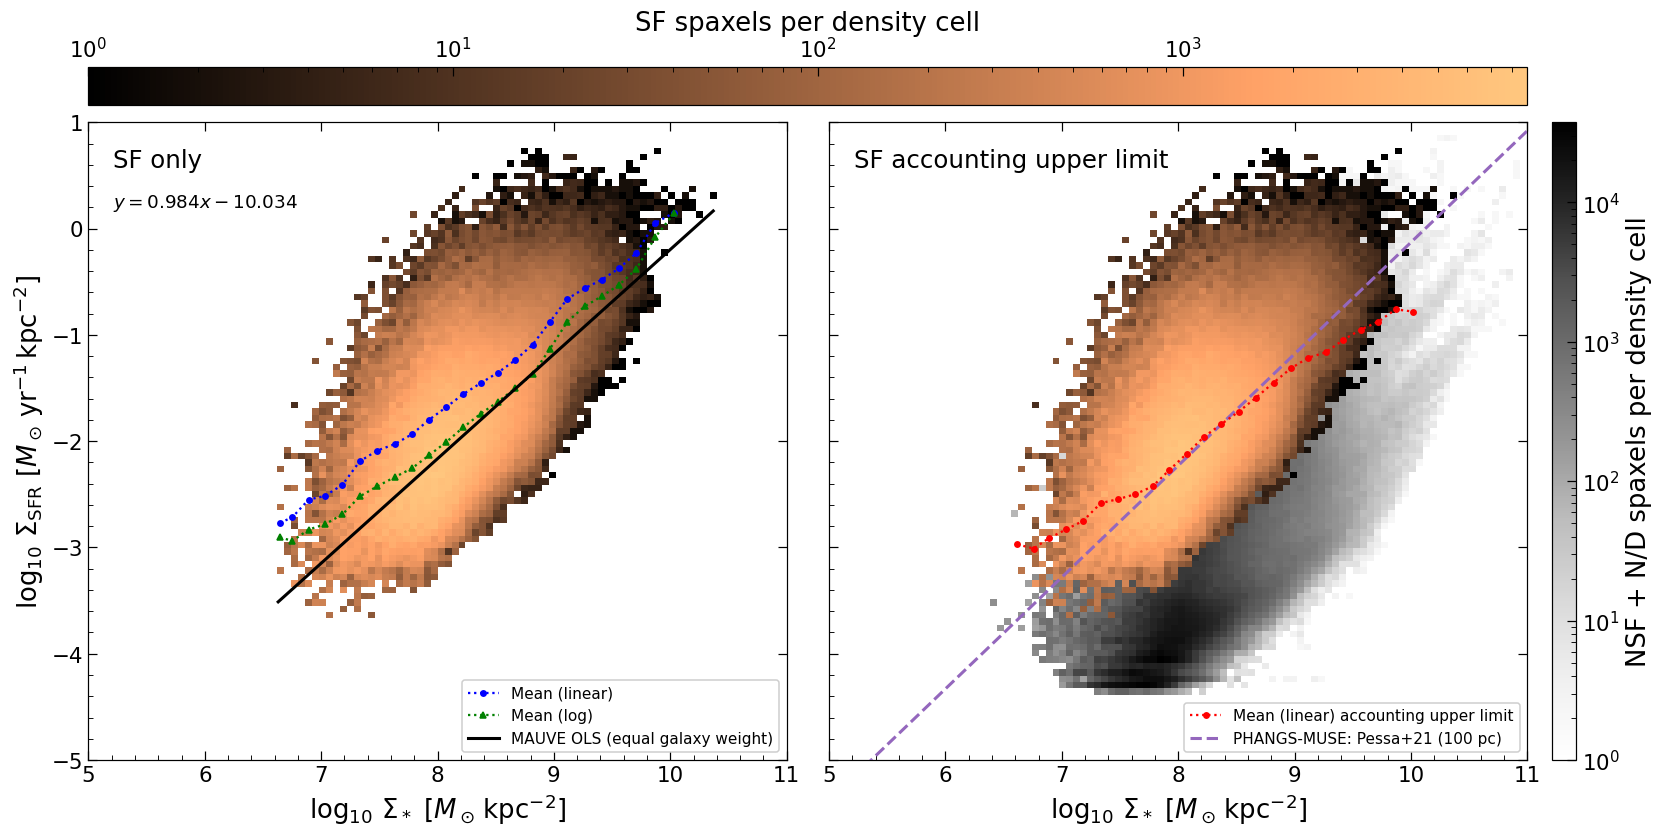

In [5]:
fig = plt.figure(figsize=(15, 7.5), layout='constrained')
gs = fig.add_gridspec(2, 3, height_ratios=[0.06, 1], width_ratios=[1, 1, 0.035])
cax_copper = fig.add_subplot(gs[0, :2])
ax_left = fig.add_subplot(gs[1,0])
ax_right = fig.add_subplot(gs[1,1], sharex=ax_left, sharey=ax_left)
cax_gray = fig.add_subplot(gs[1,2])

xe, ye = np.linspace(5,11,101), np.linspace(-6,1,118)
sf_hist, _, _ = np.histogram2d(sf_x,sf_y,bins=(xe,ye))
upper_hist, _, _ = np.histogram2d(upper_x,upper_y,bins=(xe,ye))
copper_norm = LogNorm(vmin=1, vmax=max(2,sf_hist.max()))
gray_norm = LogNorm(vmin=1, vmax=max(2,upper_hist.max()))
gray_mesh = ax_right.pcolormesh(xe,ye,np.ma.masked_less(upper_hist.T,1), cmap='Greys',
    norm=gray_norm, rasterized=True, zorder=1)
for ax in (ax_left,ax_right):
    copper_mesh = ax.pcolormesh(xe,ye,np.ma.masked_less(sf_hist.T,1),cmap='copper',
        norm=copper_norm,rasterized=True,zorder=2)
fig.colorbar(copper_mesh,cax=cax_copper,orientation='horizontal',label='SF spaxels per density cell')
cax_copper.xaxis.set_ticks_position('top'); cax_copper.xaxis.set_label_position('top')
fig.colorbar(gray_mesh,cax=cax_gray,label='NSF + N/D spaxels per density cell')

ax_left.plot(trend.x_SF,trend.log_mean_linear_SF,'o:',color='blue',
    markersize=3.5,linewidth=1.5,label='Mean (linear)',zorder=5)
ax_left.plot(trend.x_SF,trend.mean_log_SF,'^:',color='green',markersize=3.5,
    linewidth=1.5,label='Mean (log)',zorder=5)
ax_right.plot(trend.x_SF_upper,trend.log_mean_linear_SF_upper,'o:',color='red',
    markersize=3.5,linewidth=1.5,label='Mean (linear) accounting upper limit',zorder=5)
xp=np.linspace(5,11,200)
ax_right.plot(xp,PESSA_SLOPE*xp+PESSA_INTERCEPT,'--',color='tab:purple',linewidth=2,
    label='PHANGS-MUSE: Pessa+21 (100 pc)',zorder=4)

for ax,fit,title in [(ax_left,fit_left,'SF only'),(ax_right,fit_right,'SF accounting upper limit')]:
    ax.text(0.035,0.96,title,transform=ax.transAxes,va='top',fontsize=16)
    if ax is ax_left:
        xf=np.linspace(fit['xmin'],fit['xmax'],200)
        ax.plot(xf,fit['slope']*xf+fit['intercept'],'-',color='black',
                linewidth=2,label='MAUVE OLS (equal galaxy weight)',zorder=6)
        ax.text(0.035,0.89,rf'$y={fit["slope"]:.3f}x{fit["intercept"]:+.3f}$',
            transform=ax.transAxes,va='top',fontsize=12)
    ax.set_xlim(5,11);ax.set_ylim(-5,1)
    ax.set_xlabel(r'$\log_{10}\,\Sigma_*$ [$M_\odot\,{\rm kpc}^{-2}$]')
    ax.minorticks_on();ax.tick_params(top=True,right=True)
    ax.legend(loc='lower right',fontsize=10,framealpha=0.95)
ax_right.tick_params(labelleft=False)
ax_left.set_ylabel(r'$\log_{10}\,\Sigma_{\rm SFR}$ [$M_\odot\,{\rm yr}^{-1}\,{\rm kpc}^{-2}$]')
assert np.array_equal(ax_left.collections[0].norm.vmax,copper_norm.vmax)
print(f'SF density count: {int(sf_hist.sum()):,}; Upper-limit density count: {int(upper_hist.sum()):,}')
print(f'Outside histogram range: SF={sf_x.size-int(sf_hist.sum()):,}; upper limits={upper_x.size-int(upper_hist.sum()):,}')
print('Native MAUVE spaxels; individual log-log OLS with equal galaxy/product weights; NSF+ND upper-limit proxies retained')
assert ax_left.get_ylim() == (-5.0,1.0) and ax_right.get_ylim() == (-5.0,1.0)
assert not any('MAUVE OLS' in line.get_label() for line in ax_right.lines)
assert any('MAUVE OLS' in line.get_label() for line in ax_left.lines)
save_figure(fig,'rSFMS_PHANGS_MUSE')
plt.show()


## rSFMS by infall stage and SF survivor intensity

Uses the same globally filtered spaxels: inclination <80 degrees for every
product component, then finite SNR_POSTFIT >25 before SF/NSF/ND classification.
Stages come from the master catalogue, cross-checked against the geometry table.
No saved outputs from the reference notebooks are reused.

**Left:** adapted from cell 9 (one-based) of
`20260803_initial_check_rSFMS_pre_peak_infall.ipynb`. Pre-peak blue scatter is
drawn first as the background, then close-to-peak green, then post-peak red.
Each stage has a pooled-spaxel median log SFR in 0.15-dex mass bins with >=50
SF pixels. No percentile cut is reintroduced. A 95%-population contour is
calculated from each stage's smoothed histogram within the displayed window
(100x100 cells, Gaussian sigma=2). These contours summarize the displayed
SF population, not the usable-disc denominator. The black pre-peak OLS uses
individual SF log-log spaxels and the existing equal-total-galaxy/product weights.

**Right:** reproduces the upper-middle panel of the equal-galaxy 2x3 figure in
cell 15 of `20260909_check_Sigma_SFR_intensity_by_stage.ipynb`. Within fixed
0.25-dex stellar-density bins over 7.0-9.5, a galaxy/bin is eligible with
>=50 usable (SF+NSF+ND) pixels. Define `O_g=N_SF/N_usable` and
`T_g=sum(SFR_SF)/N_usable`; stage survivor intensity is
`I=mean_g(T_g)/mean_g(O_g)`, plotted as log10 I. This preserves the source
usable-area estimator; it is not the arithmetic mean of galaxy SF medians.
NSF and ND enter the usable denominator but contribute no SF-selected emission
to this conditional intensity; the upper-limit treatment in the preceding
comparison figure does not change this distinct observable.

Bands are 16th-84th percentiles of 10,000 whole-galaxy resamples within each stage
(seed 42), with the same eligible-bin rule retained. Whole galaxies are resampled
jointly across bins. The >=20-SF-pixel galaxy support count is reported, following
the source; it is not an added plotting cut. The fixed mass window alone defines
the displayed bins, with unsupported values left as NaN. All numerical support,
per-galaxy terms, and stage estimates are retained below. NGC4567_8 remains one
product/weighting group. This figure uses native sampling and existing density
corrections, and saves as `rSFMS_by_infall_stage.png` (600 dpi) and `.pdf`.


In [6]:
# One SF population per infall stage from the globally filtered loader.
sf_stage = counts.stage.to_numpy(int)[sf_group]
assert np.isin(sf_stage,[1,2,3]).all()
stage_summary = counts.groupby('stage').agg(N_groups=('galaxy','size'),N_usable=('usable','sum'),N_SF=('SF','sum'))
display(stage_summary.rename(index=STAGE_LABELS))
stage_medians = []
for stage in (1,2,3):
    select = sf_stage==stage
    x,y=sf_x[select],sf_y[select]
    assert len(x)>0, f'No SF data for stage {stage}'
    for lo,hi in zip(edges[:-1],edges[1:]):
        take=(x>=lo)&(x<hi)
        number=int(take.sum())
        stage_medians.append(dict(stage=stage,left=lo,right=hi,N_SF=number,
            x=float(np.median(x[take])) if number>=50 else (lo+hi)/2,
            median_log_SFR=float(np.median(y[take])) if number>=50 else np.nan))
stage_medians=pd.DataFrame(stage_medians)
pre=sf_stage==1
pre_peak_fit=equal_galaxy_ols(sf_x[pre],sf_y[pre],sf_group[pre])
print('Pre-peak equal-galaxy/product OLS:',{k:v for k,v in pre_peak_fit.items() if not k.startswith('group')})

# The source estimator is a ratio of equal-galaxy usable-area means.
profile_rows=[]
for stage in (1,2,3):
    galaxy_ids=counts.loc[counts.stage.eq(stage),'galaxy'].to_numpy()
    g=len(galaxy_ids)
    stage_rng=np.random.default_rng(RANDOM_SEED+100_000*(stage-1))
    draw=stage_rng.integers(0,g,size=(INTENSITY_N_BOOTSTRAP,g))
    for lo,hi in zip(INTENSITY_EDGES[:-1],INTENSITY_EDGES[1:]):
        panel=intensity_by_galaxy.loc[intensity_by_galaxy.stage.eq(stage)&np.isclose(intensity_by_galaxy.left,lo)].set_index('galaxy').reindex(galaxy_ids)
        eligible=panel.eligible.to_numpy(bool)
        nu=panel.N_usable.to_numpy(float);ns=panel.N_SF.to_numpy(float);total=panel.sum_SFR.to_numpy(float)
        occ=np.divide(ns,nu,out=np.full(g,np.nan),where=eligible)
        area=np.divide(total,nu,out=np.full(g,np.nan),where=eligible)
        O=float(np.nanmean(occ)) if eligible.any() else np.nan
        T=float(np.nanmean(area)) if eligible.any() else np.nan
        I=T/O if O>0 else np.nan
        occ_boot=np.nansum(occ[draw],axis=1)
        area_boot=np.nansum(area[draw],axis=1)
        boot_I=np.divide(area_boot,occ_boot,out=np.full(INTENSITY_N_BOOTSTRAP,np.nan),where=occ_boot>0)
        finite=boot_I[np.isfinite(boot_I)&(boot_I>0)]
        low,high=np.percentile(finite,[16,84]) if len(finite) else (np.nan,np.nan)
        if np.isfinite(I):assert np.isclose(T,O*I,rtol=1e-12)
        # Independent algebraic reconstruction of the usable-area conditional estimator.
        if eligible.any() and np.nansum(occ)>0:
            assert np.isclose(I,np.sum(total[eligible]/nu[eligible])/np.sum(ns[eligible]/nu[eligible]),rtol=1e-12)
        profile_rows.append(dict(stage=stage,left=lo,right=hi,center=(lo+hi)/2,
            N_gal_stage=g,N_gal_usable=int(eligible.sum()),
            N_gal_SF_support=int((eligible&panel.SF_support.to_numpy(bool)).sum()),
            N_usable=int(nu[eligible].sum()),N_SF=int(ns[eligible].sum()),
            occupancy=O,total_HII=T,survivor_intensity=I,lo=low,hi=high,N_finite_boot=len(finite)))
stage_intensity=pd.DataFrame(profile_rows)
assert len(stage_intensity)==30
assert (stage_intensity.N_gal_usable<=stage_intensity.N_gal_stage).all()
assert intensity_by_galaxy.N_SF.le(intensity_by_galaxy.N_usable).all()
display(stage_intensity)
print('Stage profiles: strict common cuts, whole-galaxy bootstrap and T=O*I checks passed')


,N_groups,N_usable,N_SF
stage,,,
Pre-peak,8,2703316,1420915
Close-to-peak,5,1643790,720842
Post-peak,13,2825159,222427


Pre-peak equal-galaxy/product OLS: {'slope': 1.0226405721375036, 'intercept': -10.16775467327714, 'n_spaxels': 1420915, 'n_groups': 8, 'xmin': 6.630420876331445, 'xmax': 10.3689640310496}


,stage,left,right,center,N_gal_stage,N_gal_usable,N_gal_SF_support,N_usable,N_SF,occupancy,total_HII,survivor_intensity,lo,hi,N_finite_boot
0,1,7.00,7.25,7.125,8,5,4,60705,29160,0.451148,0.001566,0.003471,0.001953,0.004926,9962
1,1,7.25,7.50,7.375,8,8,7,167362,92952,0.428005,0.002781,0.006499,0.004819,0.007915,10000
2,1,7.50,7.75,7.625,8,8,8,419725,224142,0.460185,0.004065,0.008832,0.007126,0.010248,10000
3,1,7.75,8.00,7.875,8,8,8,738692,379606,0.537134,0.008499,0.015822,0.013070,0.018358,10000
4,1,8.00,8.25,8.125,8,8,8,681067,357961,0.587476,0.014782,0.025162,0.020899,0.029151,10000
5,1,8.25,8.50,8.375,8,8,8,367286,188776,0.579272,0.023984,0.041403,0.034797,0.048640,10000
6,1,8.50,8.75,8.625,8,7,7,155162,82920,0.498566,0.045479,0.091221,0.069566,0.111867,10000
7,1,8.75,9.00,8.875,8,6,5,57865,37965,0.458405,0.081674,0.178171,0.120409,0.243750,10000
8,1,9.00,9.25,9.125,8,6,5,20837,15013,0.495805,0.156673,0.315997,0.221243,0.430825,10000
9,1,9.25,9.50,9.375,8,6,5,7514,4279,0.425975,0.228145,0.535582,0.320278,0.761090,10000


Stage profiles: strict common cuts, whole-galaxy bootstrap and T=O*I checks passed


Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/rSFMS_by_infall_stage.png
Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/rSFMS_by_infall_stage.pdf


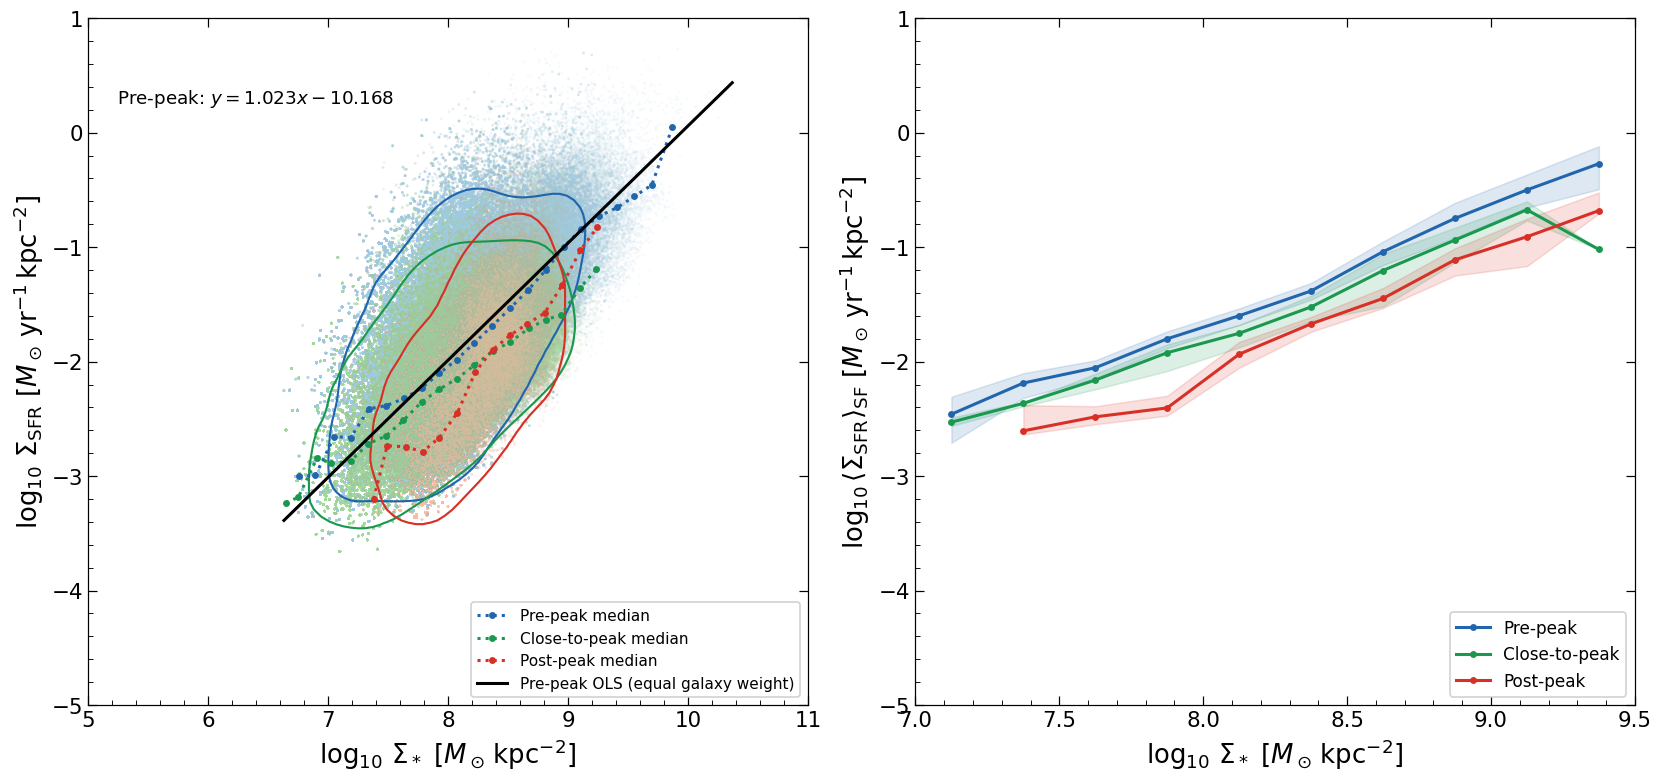

In [7]:
from scipy.ndimage import gaussian_filter
fig_stage,(ax_stage,ax_intensity)=plt.subplots(1,2,figsize=(15,7),layout='constrained')
stage_scatter_colors={1:'#9ECAE1',2:'#A1D99B',3:'#FCBBA1'}
stage_scatter_alphas={1:0.08,2:0.035,3:0.025}
stage_scatter_artists={}
for stage in (1,2,3):  # Pre-peak explicitly behind both later-stage populations.
    selected=sf_stage==stage
    x,y=sf_x[selected],sf_y[selected]
    stage_scatter_artists[stage]=ax_stage.scatter(x,y,s=3,alpha=stage_scatter_alphas[stage],
        color=stage_scatter_colors[stage],edgecolors='none',rasterized=True,zorder=stage)
    h,xe,ye=np.histogram2d(x,y,bins=100,range=[[5,11],[-5,1]])
    smooth=gaussian_filter(h,sigma=2)
    ranked=np.sort(smooth[smooth>0].ravel())[::-1]
    if len(ranked):
        index=min(np.searchsorted(np.cumsum(ranked),0.95*ranked.sum()),len(ranked)-1)
        ax_stage.contour((xe[:-1]+xe[1:])/2,(ye[:-1]+ye[1:])/2,smooth.T,
            levels=[ranked[index]],colors=[STAGE_COLORS[stage]],linewidths=1.4,zorder=4+stage/10)
    median=stage_medians.loc[stage_medians.stage.eq(stage)]
    ax_stage.plot(median.x,median.median_log_SFR,'o:',ms=3.5,lw=2,color=STAGE_COLORS[stage],
        label=STAGE_LABELS[stage]+' median',zorder=6+stage/10)
assert stage_scatter_artists[1].get_zorder()<stage_scatter_artists[2].get_zorder()<stage_scatter_artists[3].get_zorder()
xf=np.linspace(max(5,pre_peak_fit['xmin']),min(11,pre_peak_fit['xmax']),200)
ax_stage.plot(xf,pre_peak_fit['slope']*xf+pre_peak_fit['intercept'],'-',color='black',lw=2,
    label='Pre-peak OLS (equal galaxy weight)',zorder=8)
# ax_stage.text(0.04,0.96,'rSFMS by infall stage',transform=ax_stage.transAxes,va='top',fontsize=16)
ax_stage.text(0.04,0.90,rf'Pre-peak: $y={pre_peak_fit["slope"]:.3f}x{pre_peak_fit["intercept"]:+.3f}$',
    transform=ax_stage.transAxes,va='top',fontsize=12)
ax_stage.set_xlim(5,11);ax_stage.set_ylim(-5,1)
ax_stage.set_ylabel(r'$\log_{10}\,\Sigma_{\rm SFR}$ [$M_\odot\,{\rm yr}^{-1}\,{\rm kpc}^{-2}$]')
ax_stage.legend(loc='lower right',fontsize=10,framealpha=0.95)

def log_positive(a):
    a=np.asarray(a,float)
    return np.log10(np.where(np.isfinite(a)&(a>0),a,np.nan))
for stage in (1,2,3):
    panel=stage_intensity.loc[stage_intensity.stage.eq(stage)].sort_values('center')
    x=panel.center.to_numpy(float)
    y,low,high=(log_positive(panel[k]) for k in ('survivor_intensity','lo','hi'))
    ax_intensity.fill_between(x,low,high,color=STAGE_COLORS[stage],alpha=0.15)
    ax_intensity.plot(x,y,'o-',ms=3.5,lw=2,color=STAGE_COLORS[stage],label=STAGE_LABELS[stage])
ax_intensity.set_xlim(7,9.5);ax_intensity.set_ylim(-5,1)
ax_intensity.set_ylabel(r'$\log_{10}\langle\Sigma_{\rm SFR}\rangle_{\rm SF}$ [$M_\odot\,{\rm yr}^{-1}\,{\rm kpc}^{-2}$]')
# ax_intensity.text(0.04,0.96,'SF survivor intensity',transform=ax_intensity.transAxes,va='top',fontsize=16)
# ax_intensity.text(0.04,0.90,'Equal-galaxy usable-area estimator',transform=ax_intensity.transAxes,va='top',fontsize=11)
ax_intensity.legend(loc='lower right',fontsize=11,framealpha=0.95)
for axis in (ax_stage,ax_intensity):
    axis.set_xlabel(r'$\log_{10}\,\Sigma_*$ [$M_\odot\,{\rm kpc}^{-2}$]')
    axis.minorticks_on();axis.tick_params(top=True,right=True)
save_figure(fig_stage,'rSFMS_by_infall_stage')
plt.show()


## Equal-galaxy SF / ND / NSF fractions by infall stage

Adapted from the **second plot of cell 19** (one-based) in
`20260909_check_combined_SF_fraction_categories_by_stage_SNR_postfit.ipynb`.
This emits only the requested equal-galaxy fraction figure, with stellar density
in the top row, deprojected R/R_e in the bottom row, and the three infall stages
across columns. All populations come from the notebook's shared loader:
**inclination <80 degrees for every component, then finite SNR_POSTFIT >25
before SF/NSF/ND classification.** SF+ND+NSF exactly partitions the usable mask.

For each galaxy/bin, `f_category = N_category/N_usable` after the global cuts.
Only galaxy/bins with >=50 usable pixels enter the stage mean; each eligible
galaxy has total weight one. The stage fraction is the arithmetic mean of its
galaxy fractions, not a ratio of pooled pixel counts. Fixed widths are 0.25 dex
over `7.5 <= log Sigma_star < 9`, and 0.25 over `0 <= R/R_e < 1.5`.
Coverage counts remain in the tables; no additional stage-support cut is added.

R/R_e uses the same tangent-plane elliptical geometry as the reference:
the effective-radius semiaxes and position angle in `MAUVE_effective_radii.csv`.
For NGC4567_8, use the minimum component elliptical R/R_e and retain one
combined product/weighting group. Radius must be finite throughout the existing
usable mask; this is asserted without changing the preceding figures' selection.

Bands show the 16th-84th percentiles of 10,000 whole-galaxy resamples within
each stage (seed 42). A galaxy draw is shared across categories and bins, so
the category partition remains exact in every nonempty draw. Unsupported
galaxy/bins remain NaN; empty bootstrap draws are omitted from interval
percentiles and counted explicitly. Central fractions and every finite draw
must sum to one. Counts, central values, and interval bounds are verified below.

Output: `SF_NSF_ND_fractions_by_infall_stage.png` (600 dpi) and `.pdf` in
`further/Plot_Paper_2`. This fraction observable counts categories; the SFR
upper-limit proxy values used in the comparison figure do not enter it.


In [8]:
assert np.array_equal(fraction_by_galaxy.N_SF+fraction_by_galaxy.N_ND+fraction_by_galaxy.N_NSF,
    fraction_by_galaxy.N_valid)
fraction_stage_rows=[]
for stage in (1,2,3):
    galaxy_ids=counts.loc[counts.stage.eq(stage),'galaxy'].sort_values().to_numpy()
    g=len(galaxy_ids)
    fraction_rng=np.random.default_rng(RANDOM_SEED+100_000*(stage-1))
    draw=fraction_rng.integers(0,g,size=(FRACTION_N_BOOTSTRAP,g))
    for variable,bin_edges in FRACTION_EDGES.items():
        for lo,hi in zip(bin_edges[:-1],bin_edges[1:]):
            panel=fraction_by_galaxy.loc[fraction_by_galaxy.stage.eq(stage)&
                fraction_by_galaxy.variable.eq(variable)&np.isclose(fraction_by_galaxy.left,lo)
                ].set_index('galaxy').reindex(galaxy_ids)
            assert panel.N_valid.notna().all()
            denom=panel.N_valid.to_numpy(float)
            eligible=denom>=FRACTION_MIN_USABLE
            numer=panel[['N_SF','N_ND','N_NSF']].to_numpy(float)
            values=np.divide(numer,denom[:,None],out=np.full((g,3),np.nan),where=eligible[:,None])
            if eligible.any():
                assert np.allclose(values[eligible].sum(axis=1),1)
                assert np.allclose((1/denom[eligible])*denom[eligible],1)
            selected=values[draw]
            n_selected=np.isfinite(selected[:,:,0]).sum(axis=1)
            boots=np.divide(np.nansum(selected,axis=1),n_selected[:,None],
                out=np.full((FRACTION_N_BOOTSTRAP,3),np.nan),where=n_selected[:,None]>0)
            finite=n_selected>0
            if finite.any():assert np.allclose(boots[finite].sum(axis=1),1,atol=1e-12)
            central=np.mean(values[eligible],axis=0) if eligible.any() else np.full(3,np.nan)
            if eligible.any():assert np.isclose(central.sum(),1,atol=1e-12)
            rec=dict(stage=stage,variable=variable,left=lo,right=hi,center=(lo+hi)/2,
                N_gal_stage=g,N_gal_contributing=int(eligible.sum()),
                fraction_gal_contributing=float(eligible.sum()/g),N_valid=int(denom[eligible].sum()),
                N_spaxel_all=int(denom.sum()),N_finite_boot=int(finite.sum()))
            for j,label in enumerate(('SF','ND','NSF')):
                rec['f_'+label]=float(central[j])
                rec['f_'+label+'_lo'],rec['f_'+label+'_hi']=(np.percentile(boots[finite,j],[16,84]) if finite.any() else (np.nan,np.nan))
            fraction_stage_rows.append(rec)
fraction_stage_profiles=pd.DataFrame(fraction_stage_rows)
assert len(fraction_stage_profiles)==3*sum(len(edges)-1 for edges in FRACTION_EDGES.values())
supported=fraction_stage_profiles.N_gal_contributing.gt(0)
assert np.allclose(fraction_stage_profiles.loc[supported,['f_SF','f_ND','f_NSF']].sum(axis=1),1,atol=1e-12)
for label in ('SF','ND','NSF'):
    for suffix in ('','_lo','_hi'):
        assert fraction_stage_profiles.loc[supported,'f_'+label+suffix].between(0,1).all()
assert fraction_stage_profiles.N_gal_contributing.le(fraction_stage_profiles.N_gal_stage).all()
# Independent cross-check: SF fractions in mass bins match the existing occupancy estimator.
fraction_mass=fraction_stage_profiles.loc[fraction_stage_profiles.variable.eq('log_sigma_star')]
comparison=fraction_mass.merge(stage_intensity[['stage','left','occupancy']],on=['stage','left'],validate='one_to_one')
assert np.allclose(comparison.f_SF,comparison.occupancy,equal_nan=True,rtol=1e-12,atol=1e-12)
display(fraction_stage_profiles)
print('Equal-galaxy category fractions: global cuts, bin counts, unit galaxy weights, central/bootstrap partitions, bounds and occupancy cross-check passed')


,stage,variable,left,right,center,N_gal_stage,N_gal_contributing,fraction_gal_contributing,N_valid,N_spaxel_all,N_finite_boot,f_SF,f_SF_lo,f_SF_hi,f_ND,f_ND_lo,f_ND_hi,f_NSF,f_NSF_lo,f_NSF_hi
0,1,log_sigma_star,7.50,7.75,7.625,8,8,1.000,419725,419725,10000,0.460185,0.372975,0.546625,0.227370,0.136032,0.316129,0.312445,0.232610,0.395066
1,1,log_sigma_star,7.75,8.00,7.875,8,8,1.000,738692,738692,10000,0.537134,0.467570,0.604732,0.119315,0.058803,0.178194,0.343550,0.279615,0.408818
2,1,log_sigma_star,8.00,8.25,8.125,8,8,1.000,681067,681067,10000,0.587476,0.527178,0.648021,0.069672,0.035462,0.102398,0.342852,0.295680,0.389760
3,1,log_sigma_star,8.25,8.50,8.375,8,8,1.000,367286,367286,10000,0.579272,0.496530,0.663249,0.054189,0.028556,0.079822,0.366539,0.301148,0.430641
4,1,log_sigma_star,8.50,8.75,8.625,8,7,0.875,155162,155197,10000,0.498566,0.365804,0.632619,0.032747,0.017336,0.048134,0.468687,0.349686,0.587363
5,1,log_sigma_star,8.75,9.00,8.875,8,6,0.750,57865,57868,10000,0.458405,0.308928,0.606148,0.005002,0.002675,0.007330,0.536592,0.390212,0.683433
6,1,radius_re,0.00,0.25,0.125,8,8,1.000,104470,104470,10000,0.515453,0.399138,0.632669,0.012345,0.004973,0.019717,0.472202,0.359980,0.583585
7,1,radius_re,0.25,0.50,0.375,8,8,1.000,310717,310717,10000,0.576165,0.483187,0.671521,0.064397,0.022762,0.100983,0.359438,0.295009,0.423042
8,1,radius_re,0.50,0.75,0.625,8,8,1.000,502275,502275,10000,0.591115,0.534020,0.649972,0.048616,0.018641,0.077405,0.360269,0.326769,0.393211
9,1,radius_re,0.75,1.00,0.875,8,8,1.000,590715,590715,10000,0.554621,0.498897,0.610006,0.116820,0.075052,0.158283,0.328559,0.300500,0.357457


Equal-galaxy category fractions: global cuts, bin counts, unit galaxy weights, central/bootstrap partitions, bounds and occupancy cross-check passed


Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/SF_NSF_ND_fractions_by_infall_stage.png
Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/SF_NSF_ND_fractions_by_infall_stage.pdf


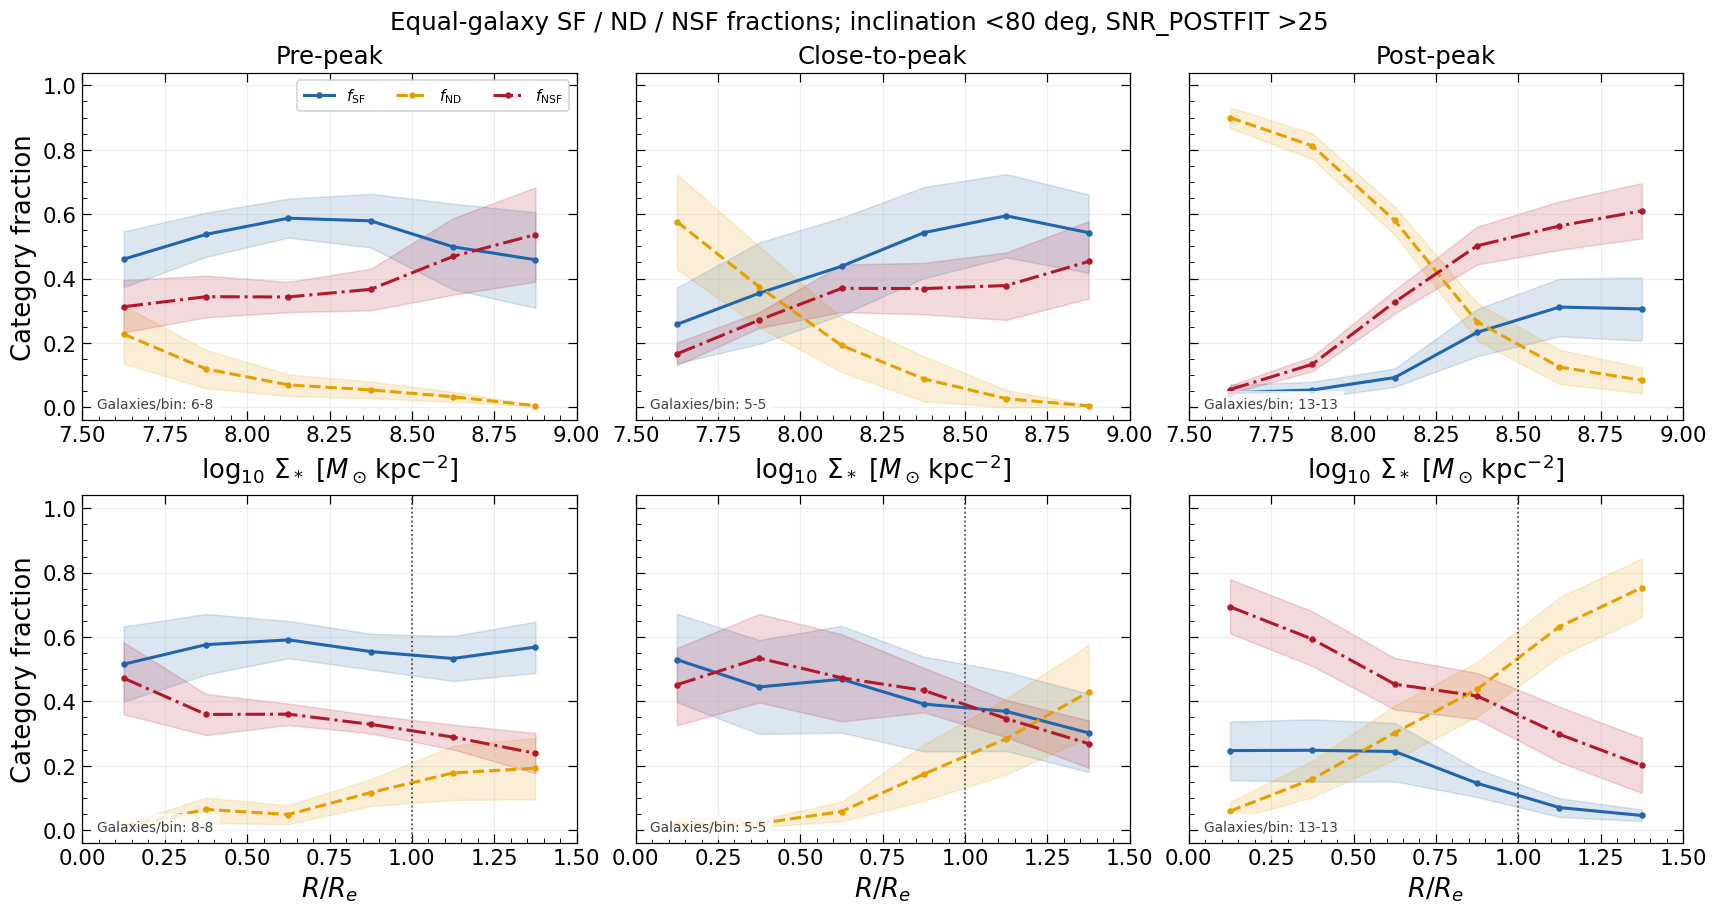

In [9]:
fig_fractions,axes_fractions=plt.subplots(2,3,figsize=(15.5,8.2),sharey=True,layout='constrained')
fraction_labels={'log_sigma_star':r'$\log_{10}\,\Sigma_*$ [$M_\odot\,{\rm kpc}^{-2}$]',
    'radius_re':r'$R/R_e$'}
for row,variable in enumerate(('log_sigma_star','radius_re')):
    for column,stage in enumerate((1,2,3)):
        ax=axes_fractions[row,column]
        panel=fraction_stage_profiles.loc[fraction_stage_profiles.stage.eq(stage)&
            fraction_stage_profiles.variable.eq(variable)].sort_values('center')
        for category,linestyle in [('SF','-'),('ND','--'),('NSF','-.')]:
            x=panel.center.to_numpy(float)
            y=panel['f_'+category].to_numpy(float)
            low=panel['f_'+category+'_lo'].to_numpy(float);high=panel['f_'+category+'_hi'].to_numpy(float)
            ax.fill_between(x,low,high,color=CATEGORY_COLORS[category],alpha=0.16)
            ax.plot(x,y,marker='o',ms=3.2,lw=2,ls=linestyle,color=CATEGORY_COLORS[category],
                label=r'$f_{\rm '+category+'}$')
        bin_edges=FRACTION_EDGES[variable]
        ax.set_xlim(bin_edges[0],bin_edges[-1]);ax.set_ylim(-0.04,1.04)
        ax.set_xlabel(fraction_labels[variable]);ax.minorticks_on();ax.tick_params(top=True,right=True)
        ax.grid(alpha=0.2)
        if row==0:ax.set_title(STAGE_LABELS[stage],fontsize=16)
        if column==0:ax.set_ylabel('Category fraction')
        if variable=='radius_re':ax.axvline(1,color='0.25',ls=':',lw=1.1)
        ax.text(0.03,0.035,f'Galaxies/bin: {panel.N_gal_contributing.min():.0f}-{panel.N_gal_contributing.max():.0f}',
            transform=ax.transAxes,fontsize=9,color='0.25',
            bbox={'facecolor':'white','edgecolor':'none','alpha':0.8})
axes_fractions[0,0].legend(ncol=3,fontsize=10,loc='upper right',framealpha=0.9)
fig_fractions.suptitle('Equal-galaxy SF / ND / NSF fractions; inclination <80 deg, SNR_POSTFIT >25',fontsize=16)
save_figure(fig_fractions,'SF_NSF_ND_fractions_by_infall_stage')
plt.show()


### Pooled-spaxel SF / ND / NSF fraction companion

The same globally filtered sample and category masks are used.
Following the pooled companion in reference cell 19, the central fraction is
`sum_g N_category / sum_g N_usable` in each stage/bin. All retained pixels enter;
the >=50 requirement is on the pooled denominator, unlike the equal-galaxy
figure's >=50 usable pixels per galaxy/bin. Bands use 10,000 whole-galaxy
resamples of numerator/denominator counts, preserving the three-category pairing.


In [10]:
pooled_fraction_rows=[]
for stage in (1,2,3):
    galaxy_ids=counts.loc[counts.stage.eq(stage),'galaxy'].sort_values().to_numpy()
    g=len(galaxy_ids)
    pool_rng=np.random.default_rng(RANDOM_SEED+500_000+100_000*(stage-1))
    draw=pool_rng.integers(0,g,size=(FRACTION_N_BOOTSTRAP,g))
    for variable,bin_edges in FRACTION_EDGES.items():
        for lo,hi in zip(bin_edges[:-1],bin_edges[1:]):
            panel=fraction_by_galaxy.loc[fraction_by_galaxy.stage.eq(stage)&fraction_by_galaxy.variable.eq(variable)&
                np.isclose(fraction_by_galaxy.left,lo)].set_index('galaxy').reindex(galaxy_ids)
            denom=panel.N_valid.to_numpy(float)
            numer=panel[['N_SF','N_ND','N_NSF']].to_numpy(float)
            assert np.array_equal(numer.sum(axis=1),denom)
            den_boot=denom[draw].sum(axis=1)
            num_boot=numer[draw].sum(axis=1)
            finite=den_boot>0
            boot=np.divide(num_boot,den_boot[:,None],out=np.full((FRACTION_N_BOOTSTRAP,3),np.nan),where=finite[:,None])
            assert np.allclose(boot[finite].sum(axis=1),1,atol=1e-12)
            supported=denom.sum()>=FRACTION_MIN_USABLE
            central=numer.sum(axis=0)/denom.sum() if supported else np.full(3,np.nan)
            if supported:assert np.isclose(central.sum(),1)
            rec=dict(stage=stage,variable=variable,left=lo,right=hi,center=(lo+hi)/2,
                N_gal_stage=g,N_gal_contributing=int((denom>0).sum()),N_valid=int(denom.sum()),N_finite_boot=int(finite.sum()))
            for j,label in enumerate(('SF','ND','NSF')):
                rec['f_'+label]=central[j]
                rec['f_'+label+'_lo'],rec['f_'+label+'_hi']=(np.percentile(boot[finite,j],[16,84]) if supported and finite.any() else (np.nan,np.nan))
            pooled_fraction_rows.append(rec)
pooled_fraction_stage_profiles=pd.DataFrame(pooled_fraction_rows)
assert len(pooled_fraction_stage_profiles)==3*sum(len(edges)-1 for edges in FRACTION_EDGES.values())
for label in ('SF','ND','NSF'):
    for suffix in ('','_lo','_hi'):
        finite_values=pooled_fraction_stage_profiles['f_'+label+suffix].dropna()
        assert finite_values.between(0,1).all()
display(pooled_fraction_stage_profiles)
print('Pooled fractions: strict shared masks, pooled-count estimator and paired-bootstrap partition checks passed')


,stage,variable,left,right,center,N_gal_stage,N_gal_contributing,N_valid,N_finite_boot,f_SF,f_SF_lo,f_SF_hi,f_ND,f_ND_lo,f_ND_hi,f_NSF,f_NSF_lo,f_NSF_hi
0,1,log_sigma_star,7.50,7.75,7.625,8,8,419725,10000,0.534021,0.432797,0.601499,0.191704,0.124122,0.294850,0.274275,0.248041,0.301901
1,1,log_sigma_star,7.75,8.00,7.875,8,8,738692,10000,0.513889,0.463748,0.570730,0.171561,0.116796,0.229980,0.314549,0.283515,0.339154
2,1,log_sigma_star,8.00,8.25,8.125,8,8,681067,10000,0.525589,0.461802,0.601053,0.119254,0.071481,0.168390,0.355157,0.309654,0.388395
3,1,log_sigma_star,8.25,8.50,8.375,8,8,367286,10000,0.513975,0.431254,0.597662,0.062205,0.036117,0.093505,0.423820,0.357972,0.486359
4,1,log_sigma_star,8.50,8.75,8.625,8,8,155197,10000,0.534514,0.355429,0.666062,0.021817,0.010660,0.038728,0.443668,0.322789,0.606309
5,1,log_sigma_star,8.75,9.00,8.875,8,7,57868,10000,0.656114,0.457085,0.788601,0.002402,0.001089,0.004479,0.341484,0.210283,0.538560
6,1,radius_re,0.00,0.25,0.125,8,8,104470,10000,0.340481,0.248223,0.494462,0.014521,0.010274,0.018394,0.644999,0.494175,0.733884
7,1,radius_re,0.25,0.50,0.375,8,8,310717,10000,0.432673,0.340752,0.576178,0.099351,0.046932,0.154388,0.467976,0.331499,0.534853
8,1,radius_re,0.50,0.75,0.625,8,8,502275,10000,0.552986,0.481984,0.628323,0.075463,0.036268,0.114516,0.371551,0.331144,0.406202
9,1,radius_re,0.75,1.00,0.875,8,8,590715,10000,0.483140,0.438563,0.545864,0.177786,0.137763,0.202550,0.339074,0.308006,0.365579


Pooled fractions: strict shared masks, pooled-count estimator and paired-bootstrap partition checks passed


Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/SF_NSF_ND_fractions_by_infall_stage_pooled.png
Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/SF_NSF_ND_fractions_by_infall_stage_pooled.pdf


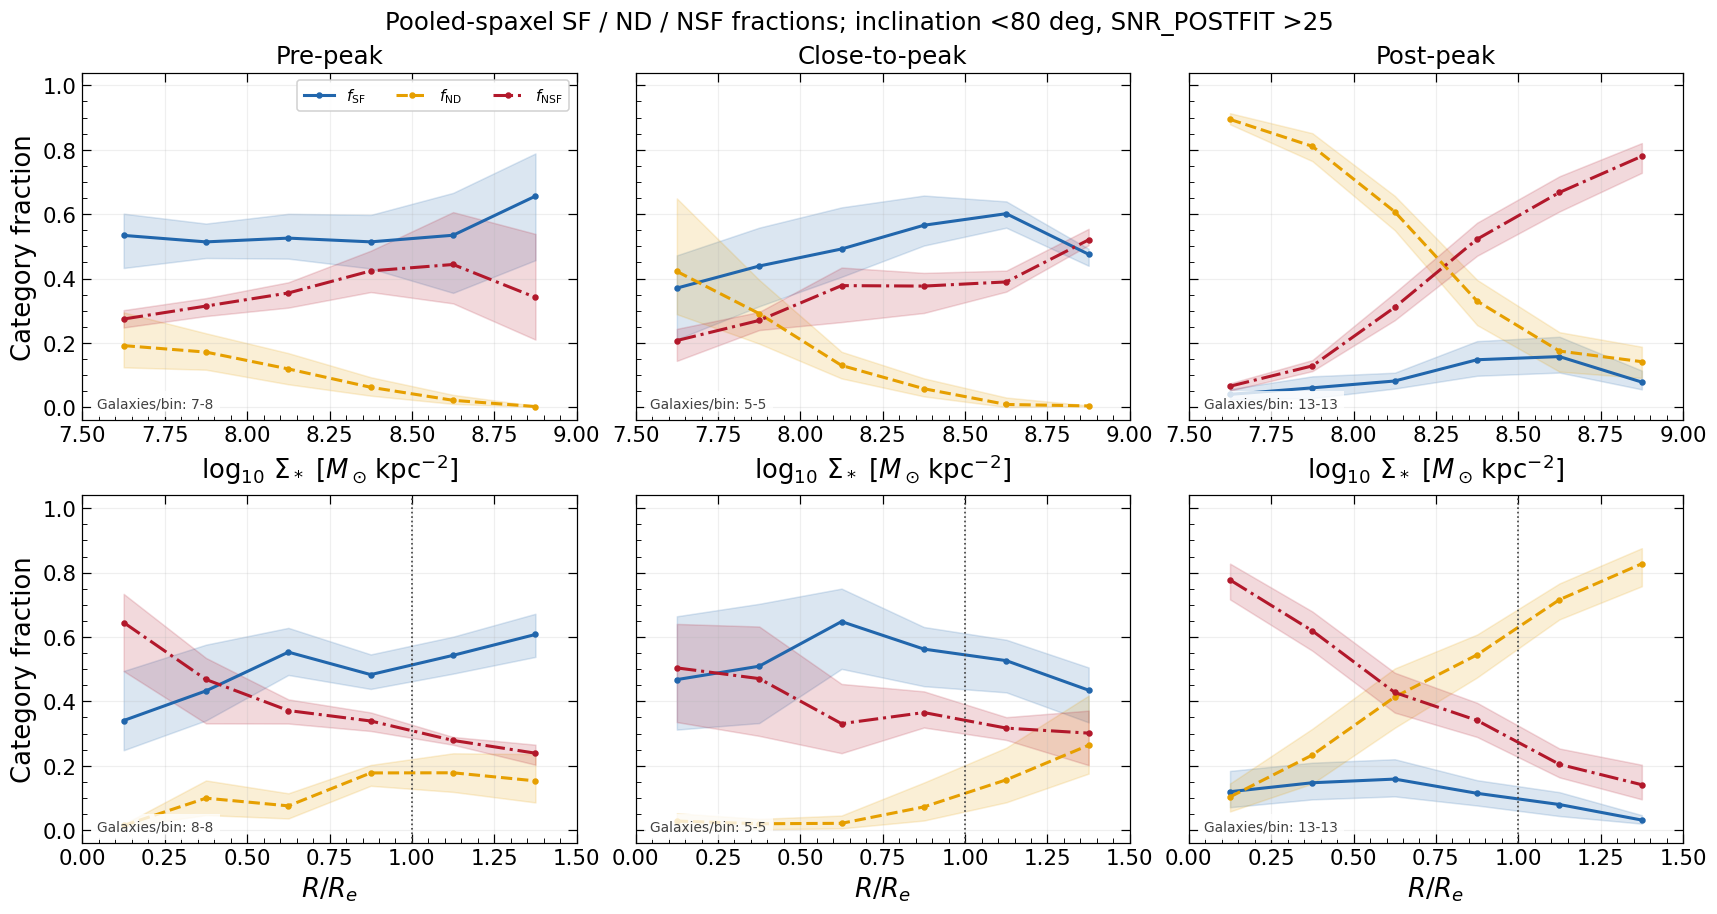

In [11]:
fig_fractions_pooled,axes_fractions=plt.subplots(2,3,figsize=(15.5,8.2),sharey=True,layout='constrained')
fraction_labels={'log_sigma_star':r'$\log_{10}\,\Sigma_*$ [$M_\odot\,{\rm kpc}^{-2}$]',
    'radius_re':r'$R/R_e$'}
for row,variable in enumerate(('log_sigma_star','radius_re')):
    for column,stage in enumerate((1,2,3)):
        ax=axes_fractions[row,column]
        panel=pooled_fraction_stage_profiles.loc[pooled_fraction_stage_profiles.stage.eq(stage)&
            pooled_fraction_stage_profiles.variable.eq(variable)].sort_values('center')
        for category,linestyle in [('SF','-'),('ND','--'),('NSF','-.')]:
            x=panel.center.to_numpy(float)
            y=panel['f_'+category].to_numpy(float)
            low=panel['f_'+category+'_lo'].to_numpy(float);high=panel['f_'+category+'_hi'].to_numpy(float)
            ax.fill_between(x,low,high,color=CATEGORY_COLORS[category],alpha=0.16)
            ax.plot(x,y,marker='o',ms=3.2,lw=2,ls=linestyle,color=CATEGORY_COLORS[category],
                label=r'$f_{\rm '+category+'}$')
        bin_edges=FRACTION_EDGES[variable]
        ax.set_xlim(bin_edges[0],bin_edges[-1]);ax.set_ylim(-0.04,1.04)
        ax.set_xlabel(fraction_labels[variable]);ax.minorticks_on();ax.tick_params(top=True,right=True)
        ax.grid(alpha=0.2)
        if row==0:ax.set_title(STAGE_LABELS[stage],fontsize=16)
        if column==0:ax.set_ylabel('Category fraction')
        if variable=='radius_re':ax.axvline(1,color='0.25',ls=':',lw=1.1)
        ax.text(0.03,0.035,f'Galaxies/bin: {panel.N_gal_contributing.min():.0f}-{panel.N_gal_contributing.max():.0f}',
            transform=ax.transAxes,fontsize=9,color='0.25',
            bbox={'facecolor':'white','edgecolor':'none','alpha':0.8})
axes_fractions[0,0].legend(ncol=3,fontsize=10,loc='upper right',framealpha=0.9)
fig_fractions_pooled.suptitle('Pooled-spaxel SF / ND / NSF fractions; inclination <80 deg, SNR_POSTFIT >25',fontsize=16)
save_figure(fig_fractions_pooled,'SF_NSF_ND_fractions_by_infall_stage_pooled')
plt.show()


## NSF emission-line surface densities and BPT ratios

Adapted from cell 19 (`show_lines("NSF")`) and cell 27 (`show_ratios("NSF")`)
of `20260930_check_emission_line_fading_BPT_ratios_Halpha_sigma_SF_NSF_by_stage.ipynb`.
Both equal-galaxy and pooled-spaxel versions are retained, producing four figures.
Columns show stellar density and R/R_e; rows show five line intensities or three
BPT ratios. All use the notebook's strict global **inclination <80 degrees** and
**finite SNR_POSTFIT >25 before classification** rules.

Only NSF spaxels with common raw detections of Halpha, Hbeta, [O III]5007,
[N II]6583, [S II]6716 and [S II]6731 enter. Detection uses each product's CUT_SN
and NOISE and finite positive flux errors. Corrected fluxes must be finite and
positive on that common footprint; this is asserted. No ND values enter.
The five plotted lines share exactly the same pixels and galaxy/bin support.

For each galaxy, `log I_Halpha = LOGSFR_SURFACE_DENSITY - log10(SFRCOEF)`;
the other corrected line surface densities are `I_Halpha * F_line,corr/F_Halpha,corr`.
[S II] sums the two components. Stored surface-density/inclination corrections
are preserved; none is applied twice. Units are erg s^-1 kpc^-2. These are
mean intensities conditional on the matched NSF footprint, not per-total-disc
luminosity or median pixel intensities.

Use 0.25-dex mass bins on [7.5,9) and 0.25 radius bins on [0,1.5). A galaxy/bin
must have >=50 usable pixels and >=20 common six-line NSF pixels. Equal-galaxy
profiles are arithmetic means of the per-galaxy linear line intensities; pooled
profiles sum line luminosity surface-density values and divide by the common
pixel count, over the same supported galaxies. This reproduces the source's
two estimators; no extra stage-level support cut is added.

BPT curves are **log ratios of stage mean linear intensities**, not means of
individual log ratios: OIII/Hbeta, NII/Halpha and (SII6716+6731)/Halpha.
10,000 whole-galaxy bootstrap resamples produce 16th-84th percentile intervals.
The same draw indices are used for all five lines within each branch, preserving
numerator-denominator pairing. Empty draws and unsupported bins remain NaN;
support and finite-draw counts are retained. The existing combined NGC4567_8
product remains one weighting/geometry group. The SF/NSF/ND selections and
preceding figures are unchanged by these additional diagnostic detection cuts.


In [12]:
assert (nsf_lines_by_galaxy.N_common<=nsf_lines_by_galaxy.N_NSF).all()
assert (nsf_lines_by_galaxy.N_NSF<=nsf_lines_by_galaxy.N_valid).all()
assert np.array_equal(nsf_lines_by_galaxy.supported,
    (nsf_lines_by_galaxy.N_valid>=FRACTION_MIN_USABLE)&(nsf_lines_by_galaxy.N_common>=NSF_MIN_COMMON))
display(nsf_line_provenance)
line_profile_rows=[];ratio_profile_rows=[];nsf_bootstrap_draws={}
ratio_specs=(('OIII5006','HB4861'),('NII6583','HA6562'),('SII_SUM','HA6562'))
for stage in (1,2,3):
    galaxy_ids=counts.loc[counts.stage.eq(stage),'galaxy'].sort_values().to_numpy()
    g=len(galaxy_ids)
    for vi,(variable,bin_edges) in enumerate(FRACTION_EDGES.items()):
        for bi,(lo,hi) in enumerate(zip(bin_edges[:-1],bin_edges[1:])):
            panel=nsf_lines_by_galaxy.loc[nsf_lines_by_galaxy.stage.eq(stage)&
                nsf_lines_by_galaxy.variable.eq(variable)&np.isclose(nsf_lines_by_galaxy.left,lo)
                ].set_index('galaxy').reindex(galaxy_ids)
            assert panel.N_common.notna().all()
            support=panel.supported.to_numpy(bool)
            per_gal_mean=panel[['mean_'+line for line in NSF_LINE_ORDER]].to_numpy(float)
            means=np.where(support[:,None],per_gal_mean,np.nan)
            sums=np.where(support[:,None],panel[['sum_'+line for line in NSF_LINE_ORDER]].to_numpy(float),0.)
            pixel_counts=np.where(support,panel.N_common.to_numpy(float),0.)
            for branch,seed_base in [('equal_galaxy',13_000_000),('pooled_spaxel',14_000_000)]:
                line_rng=np.random.default_rng(RANDOM_SEED+seed_base+1_000_000*(stage-1)+100_000*vi+10_000+bi)
                draw=line_rng.integers(0,g,size=(NSF_N_BOOTSTRAP,g))
                if branch=='equal_galaxy':
                    n_draw=support[draw].sum(axis=1)
                    boot=np.divide(np.nansum(means[draw],axis=1),n_draw[:,None],
                        out=np.full((NSF_N_BOOTSTRAP,5),np.nan),where=n_draw[:,None]>0)
                    central=np.mean(means[support],axis=0) if support.any() else np.full(5,np.nan)
                else:
                    n_draw=pixel_counts[draw].sum(axis=1)
                    boot=np.divide(sums[draw].sum(axis=1),n_draw[:,None],
                        out=np.full((NSF_N_BOOTSTRAP,5),np.nan),where=n_draw[:,None]>0)
                    central=sums.sum(axis=0)/pixel_counts.sum() if pixel_counts.sum()>0 else np.full(5,np.nan)
                finite=n_draw>0
                assert np.isfinite(boot[finite]).all() and (boot[finite]>0).all()
                assert np.array_equal(np.isfinite(boot).all(axis=1),finite)
                key=(branch,stage,variable,float(lo))
                nsf_bootstrap_draws[key]=boot
                common=dict(branch=branch,stage=stage,variable=variable,left=lo,right=hi,center=(lo+hi)/2,
                    N_gal_support=int(support.sum()),N_spaxel_support=int(pixel_counts.sum()),N_finite_draws=int(finite.sum()))
                for li,line in enumerate(NSF_LINE_ORDER):
                    low,high=np.percentile(boot[finite,li],[16,84]) if finite.any() else (np.nan,np.nan)
                    line_profile_rows.append(dict(common,line=line,mean_surface=central[li],lo=low,hi=high))
                for numerator,denominator in ratio_specs:
                    ni,di=NSF_LINE_ORDER.index(numerator),NSF_LINE_ORDER.index(denominator)
                    value=np.log10(central[ni]/central[di]) if support.any() else np.nan
                    ratio_draw=np.log10(boot[finite,ni]/boot[finite,di])
                    low,high=np.percentile(ratio_draw,[16,84]) if len(ratio_draw) else (np.nan,np.nan)
                    if support.any():
                        assert np.isclose(value,np.log10(central[ni])-np.log10(central[di]),atol=1e-12)
                    ratio_profile_rows.append(dict(common,line=numerator,denominator=denominator,value=value,lo=low,hi=high))
nsf_line_profiles=pd.DataFrame(line_profile_rows)
nsf_ratio_profiles=pd.DataFrame(ratio_profile_rows)
assert len(nsf_line_profiles)==2*3*sum(len(edges)-1 for edges in FRACTION_EDGES.values())*len(NSF_LINE_ORDER)
assert len(nsf_ratio_profiles)==2*3*sum(len(edges)-1 for edges in FRACTION_EDGES.values())*len(ratio_specs)
for _,group in nsf_line_profiles.groupby(['branch','stage','variable','left']):
    assert group.N_gal_support.nunique()==1 and group.N_spaxel_support.nunique()==1
    assert len(group)==5
for table in (nsf_line_profiles,nsf_ratio_profiles):
    assert (table.N_finite_draws<=NSF_N_BOOTSTRAP).all()
    central_key='mean_surface' if 'mean_surface' in table else 'value'
    supported=table.N_gal_support.gt(0)
    assert np.isfinite(table.loc[supported,[central_key,'lo','hi']]).all().all()
    assert (table.loc[supported,'lo']<=table.loc[supported,'hi']).all()
display(nsf_line_profiles);display(nsf_ratio_profiles)
print('NSF line/ratio profiles: shared corrected-line footprint, support, units construction and paired-bootstrap checks passed')


,galaxy,stage,SFRCOEF,CUT_SN,NOISE,DUSTLAW,N_NSF,N_common
0,IC3392,3,4.983582e-42,3.0,20.0,calzetti,9123,4760
1,NGC4064,3,4.983582e-42,3.0,20.0,calzetti,33921,24756
2,NGC4189,1,4.983582e-42,3.0,20.0,calzetti,34012,21174
3,NGC4254,1,4.983582e-42,3.0,20.0,calzetti,163358,115258
4,NGC4293,3,4.983582e-42,3.0,20.0,calzetti,63400,35414
5,NGC4294,1,4.983582e-42,3.0,20.0,calzetti,51426,36397
6,NGC4298,2,4.983582e-42,3.0,20.0,calzetti,43104,18427
7,NGC4321,1,4.983582e-42,3.0,20.0,calzetti,329655,200509
8,NGC4351,1,4.983582e-42,3.0,20.0,calzetti,16682,10461
9,NGC4380,3,4.983582e-42,3.0,20.0,calzetti,51190,16489


,branch,stage,variable,left,right,center,N_gal_support,N_spaxel_support,N_finite_draws,line,mean_surface,lo,hi
0,equal_galaxy,1,log_sigma_star,7.50,7.75,7.625,8,58064,10000,HA6562,4.956248e+38,4.419361e+38,5.505111e+38
1,equal_galaxy,1,log_sigma_star,7.50,7.75,7.625,8,58064,10000,HB4861,1.733505e+38,1.545714e+38,1.925390e+38
2,equal_galaxy,1,log_sigma_star,7.50,7.75,7.625,8,58064,10000,OIII5006,1.567017e+38,1.270548e+38,1.859545e+38
3,equal_galaxy,1,log_sigma_star,7.50,7.75,7.625,8,58064,10000,NII6583,1.947005e+38,1.626612e+38,2.275336e+38
4,equal_galaxy,1,log_sigma_star,7.50,7.75,7.625,8,58064,10000,SII_SUM,2.448324e+38,2.226623e+38,2.676699e+38
...,...,...,...,...,...,...,...,...,...,...,...,...,...
355,pooled_spaxel,3,radius_re,1.25,1.50,1.375,8,32712,10000,HA6562,5.207069e+38,2.716939e+38,6.500212e+38
356,pooled_spaxel,3,radius_re,1.25,1.50,1.375,8,32712,10000,HB4861,1.824667e+38,9.557973e+37,2.276365e+38
357,pooled_spaxel,3,radius_re,1.25,1.50,1.375,8,32712,10000,OIII5006,2.044890e+38,1.508769e+38,2.432761e+38
358,pooled_spaxel,3,radius_re,1.25,1.50,1.375,8,32712,10000,NII6583,3.689676e+38,2.136192e+38,4.522473e+38


,branch,stage,variable,left,right,center,N_gal_support,N_spaxel_support,N_finite_draws,line,denominator,value,lo,hi
0,equal_galaxy,1,log_sigma_star,7.50,7.75,7.625,8,58064,10000,OIII5006,HB4861,-0.043851,-0.109248,0.009449
1,equal_galaxy,1,log_sigma_star,7.50,7.75,7.625,8,58064,10000,NII6583,HA6562,-0.405786,-0.465813,-0.351492
2,equal_galaxy,1,log_sigma_star,7.50,7.75,7.625,8,58064,10000,SII_SUM,HA6562,-0.306284,-0.324794,-0.286723
3,pooled_spaxel,1,log_sigma_star,7.50,7.75,7.625,8,58064,10000,OIII5006,HB4861,-0.099912,-0.163086,-0.001652
4,pooled_spaxel,1,log_sigma_star,7.50,7.75,7.625,8,58064,10000,NII6583,HA6562,-0.400687,-0.480310,-0.354290
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
211,equal_galaxy,3,radius_re,1.25,1.50,1.375,8,32712,10000,NII6583,HA6562,-0.148264,-0.176546,-0.121054
212,equal_galaxy,3,radius_re,1.25,1.50,1.375,8,32712,10000,SII_SUM,HA6562,-0.268055,-0.293275,-0.247987
213,pooled_spaxel,3,radius_re,1.25,1.50,1.375,8,32712,10000,OIII5006,HB4861,0.049486,-0.029794,0.220410
214,pooled_spaxel,3,radius_re,1.25,1.50,1.375,8,32712,10000,NII6583,HA6562,-0.149605,-0.169608,-0.099963


NSF line/ratio profiles: shared corrected-line footprint, support, units construction and paired-bootstrap checks passed


In [13]:
NSF_RATIO_LABELS={'OIII5006':r'$\log_{10}([\mathrm{O\,III}]/\mathrm{H}\beta)$',
    'NII6583':r'$\log_{10}([\mathrm{N\,II}]/\mathrm{H}\alpha)$',
    'SII_SUM':r'$\log_{10}([\mathrm{S\,II}]/\mathrm{H}\alpha)$'}
def plot_nsf_paper_profiles(branch,kind):
    is_lines=kind=='lines'
    table=nsf_line_profiles if is_lines else nsf_ratio_profiles
    line_order=NSF_LINE_ORDER if is_lines else tuple(NSF_RATIO_LABELS)
    branch_label='Equal-galaxy' if branch=='equal_galaxy' else 'Pooled-spaxel'
    fig_nsf,axes=plt.subplots(len(line_order),2,figsize=(12,2.8*len(line_order)),
        squeeze=False,sharex='col',layout='constrained')
    for row,line in enumerate(line_order):
        for column,variable in enumerate(('log_sigma_star','radius_re')):
            ax=axes[row,column]
            for stage in (1,2,3):
                panel=table.loc[table.branch.eq(branch)&table.line.eq(line)&
                    table.variable.eq(variable)&table.stage.eq(stage)].sort_values('center')
                x=panel.center.to_numpy(float)
                center_key='mean_surface' if is_lines else 'value'
                y,low,high=(panel[k].to_numpy(float) for k in (center_key,'lo','hi'))
                if is_lines:y,low,high=(log_positive(v) for v in (y,low,high))
                ax.plot(x,y,color=STAGE_COLORS[stage],marker='o',ms=3,lw=1.8,label=STAGE_LABELS[stage])
                ax.fill_between(x,low,high,color=STAGE_COLORS[stage],alpha=0.15,linewidth=0)
            ax.set_xlim(FRACTION_EDGES[variable][0],FRACTION_EDGES[variable][-1])
            ax.set_title(NSF_LINE_LABELS[line] if is_lines else NSF_RATIO_LABELS[line],fontsize=12)
            ax.set_xlabel(fraction_labels[variable],fontsize=12)
            ax.set_ylabel(r'$\log_{10} I_\ell$ [erg s$^{-1}$ kpc$^{-2}$]' if is_lines else r'$\log_{10}$ ratio',fontsize=11)
            ax.tick_params(labelsize=10,top=True,right=True);ax.minorticks_on();ax.grid(alpha=0.2)
    axes[0,0].legend(frameon=False,fontsize=10,loc='best')
    fig_nsf.suptitle(branch_label+(' NSF corrected line surface densities' if is_lines else ' NSF BPT ratios'),fontsize=16)
    stem=('NSF_emission_line_surface_densities_' if is_lines else 'NSF_BPT_ratios_')+branch
    save_figure(fig_nsf,stem)
    plt.show()
    plt.close(fig_nsf)


Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/NSF_emission_line_surface_densities_equal_galaxy.png
Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/NSF_emission_line_surface_densities_equal_galaxy.pdf


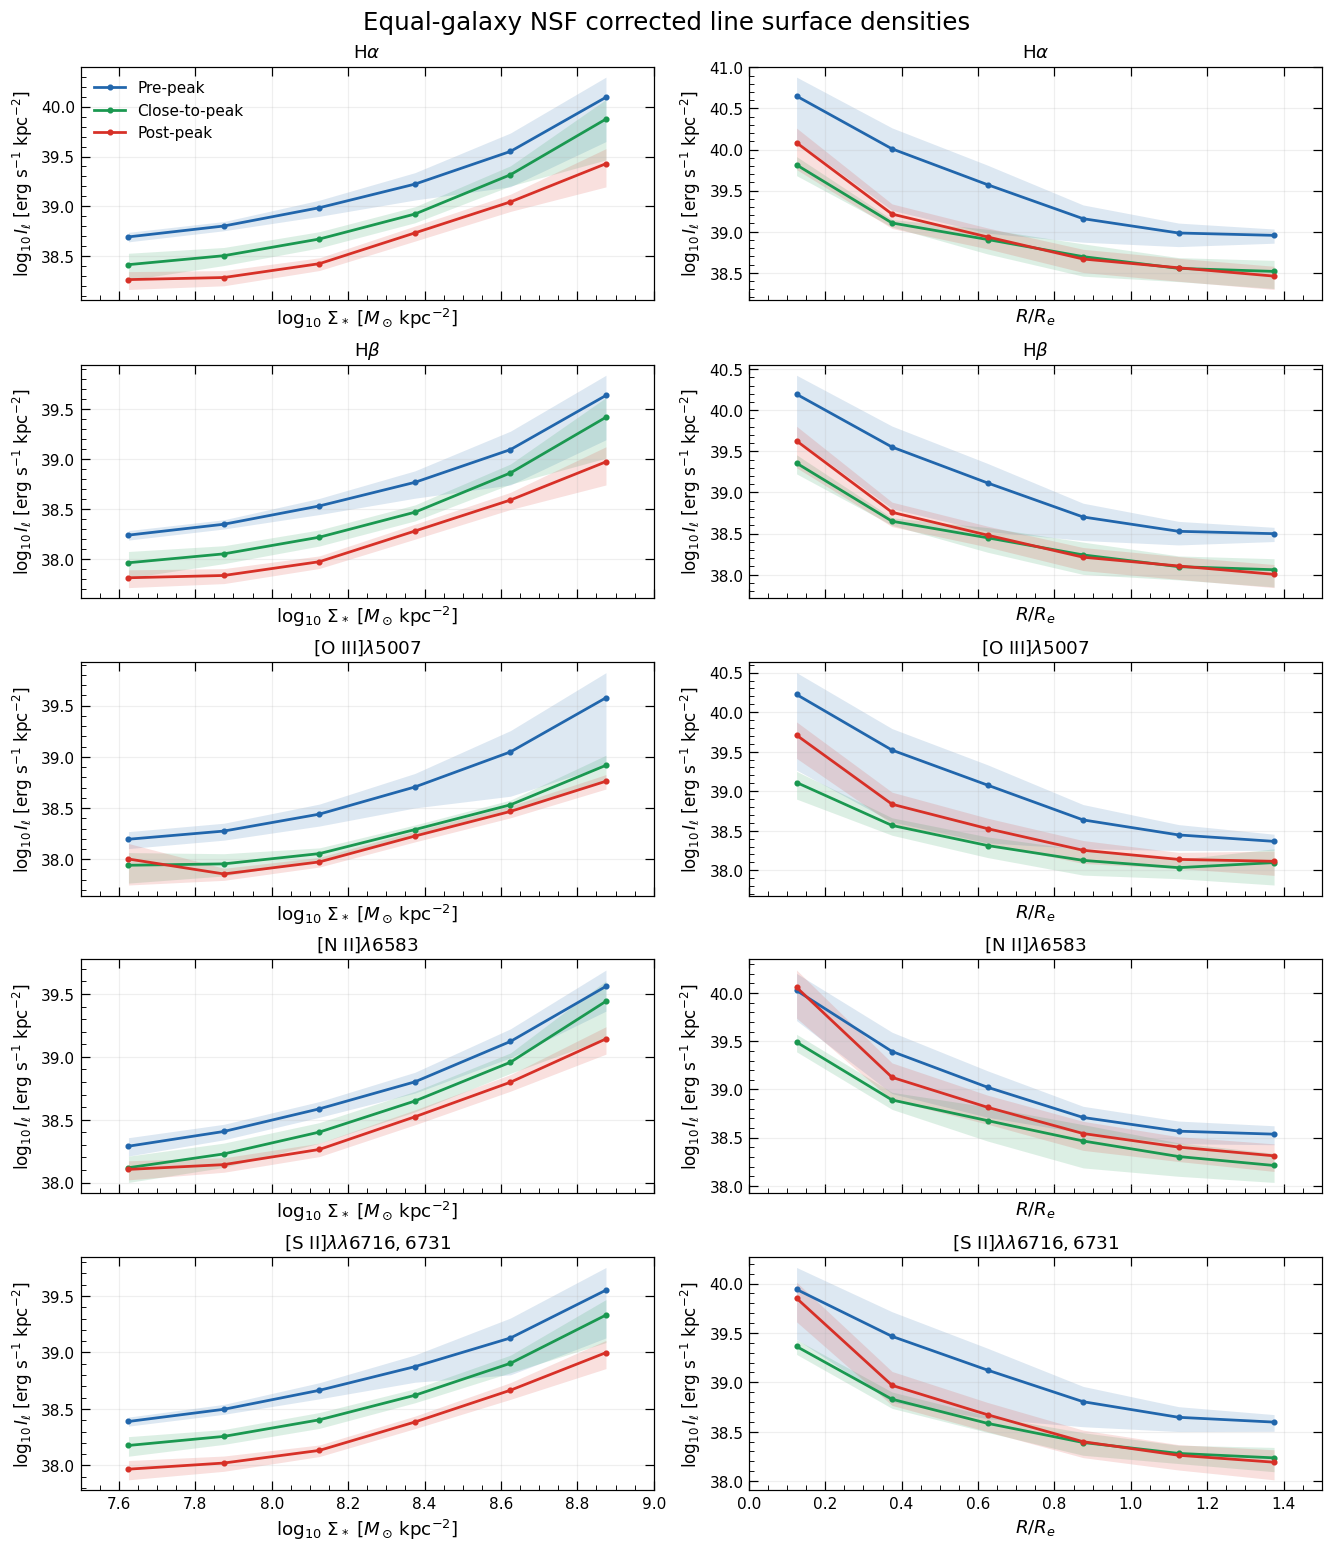

Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/NSF_emission_line_surface_densities_pooled_spaxel.png
Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/NSF_emission_line_surface_densities_pooled_spaxel.pdf


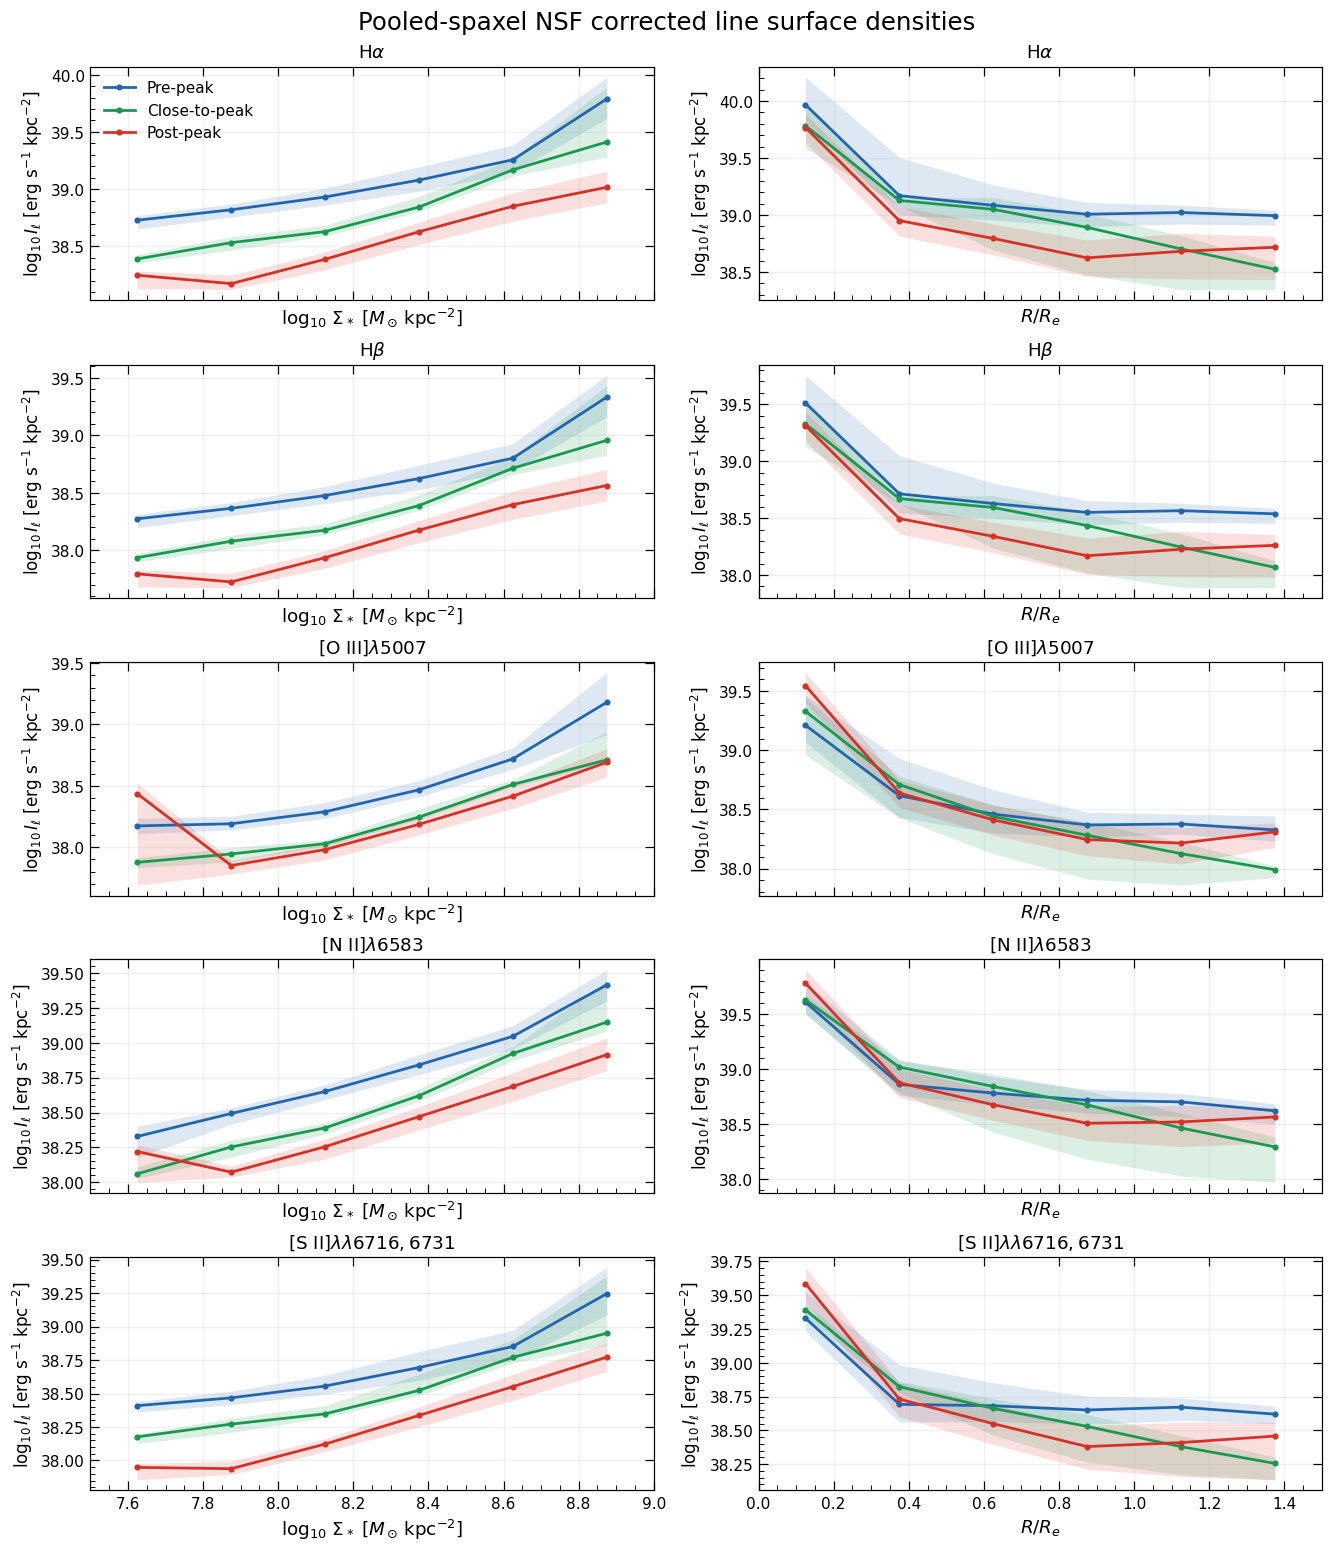

In [14]:
# Source cell 19: NSF absolute lines, both weighting schemes.
for nsf_branch in ('equal_galaxy','pooled_spaxel'):
    plot_nsf_paper_profiles(nsf_branch,'lines')

Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/NSF_BPT_ratios_equal_galaxy.png
Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/NSF_BPT_ratios_equal_galaxy.pdf


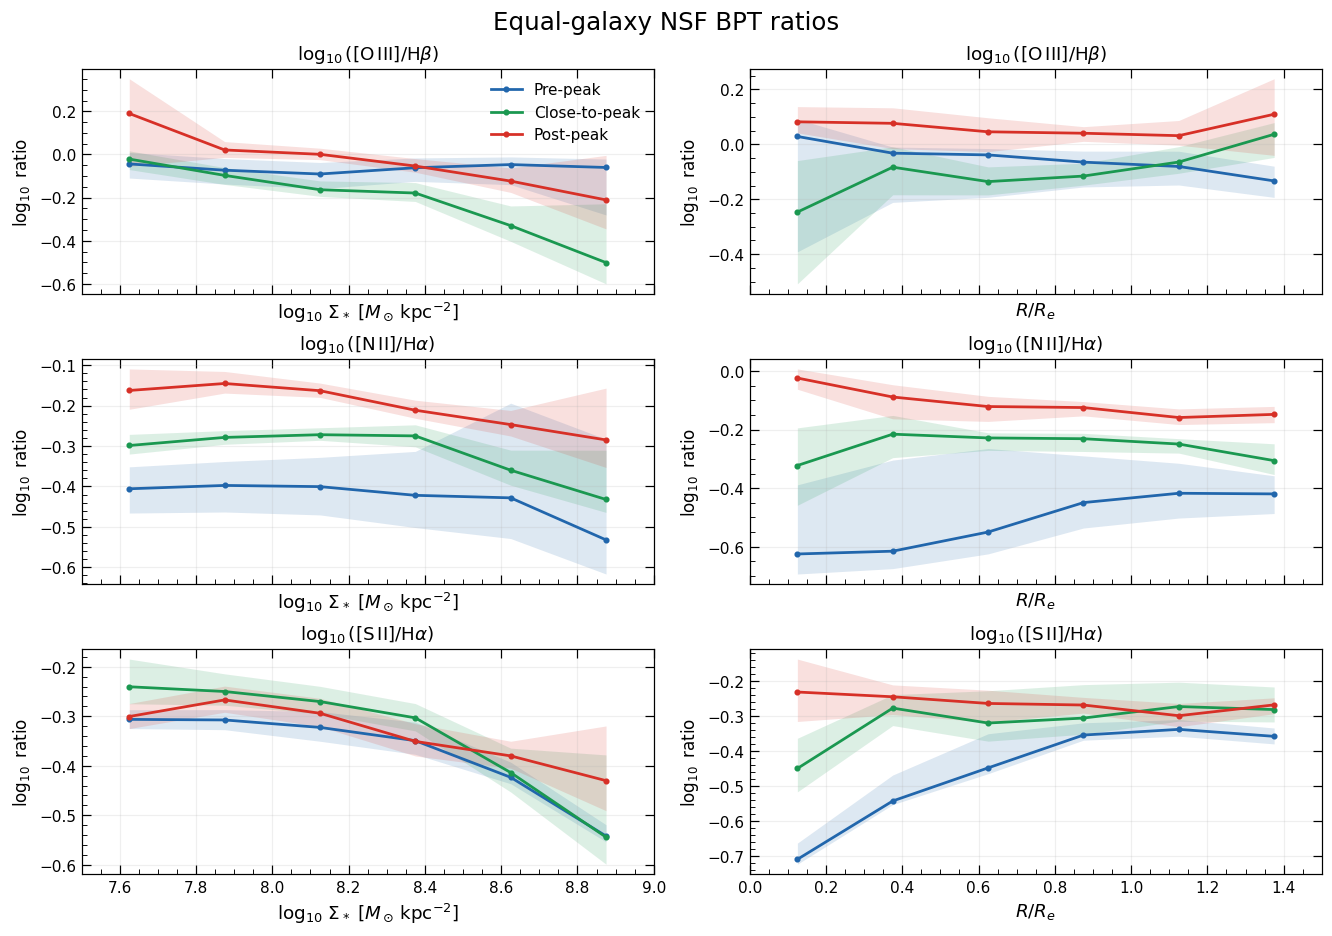

Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/NSF_BPT_ratios_pooled_spaxel.png
Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/NSF_BPT_ratios_pooled_spaxel.pdf


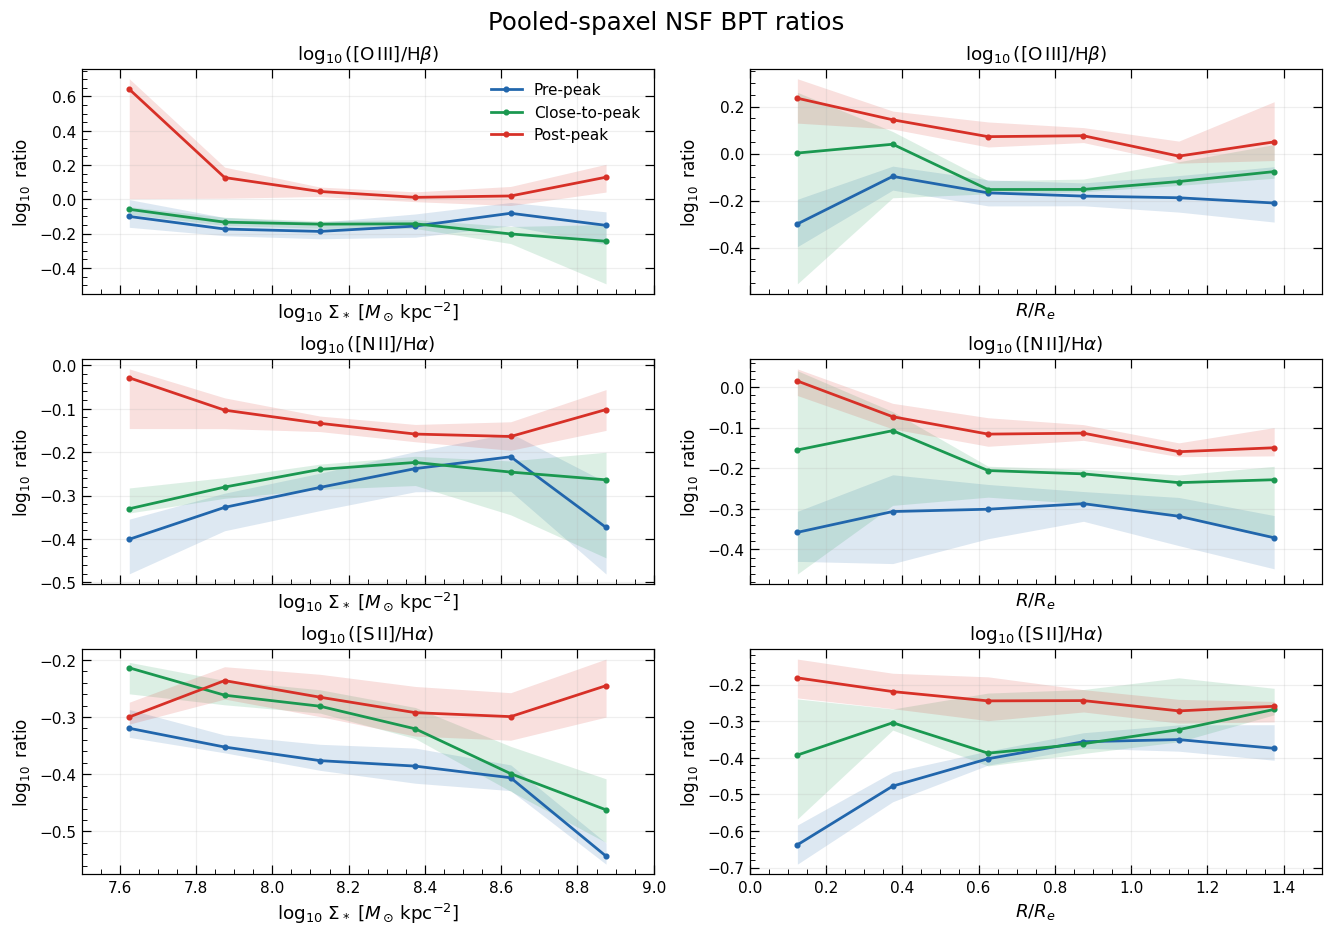

In [15]:
# Source cell 27: NSF BPT ratios, both weighting schemes.
for nsf_branch in ('equal_galaxy','pooled_spaxel'):
    plot_nsf_paper_profiles(nsf_branch,'ratios')

## NSF EW(Halpha), intrinsic Halpha dispersion, and [S II] doublet ratio

Two versions follow the existing NSF BPT-profile layout: equal-galaxy and
pooled-spaxel, with mass and R/R_e in the columns and three diagnostics in rows.
The globally filtered NSF category is unchanged: **inclination <80 degrees**
and **finite SNR_POSTFIT >25 before SF/NSF/ND classification**.

- EW uses finite `PROXY_EWHA` within NSF, in Angstrom, without another EW cut.
- Intrinsic Halpha **velocity dispersion** uses finite
  `sqrt(HA6562_SIGMA**2 - HA6562_SIGMA_CORR**2)`, positive radicand only, in km/s.
  This is the line-width diagnostic, not scatter around an rSFMS fit. No <45
  cut is imposed on NSF dispersion measurements.
- The linear [S II] ratio is corrected lambda6716/lambda6731 (stored HDUs
  `SII6716`/`SII6730`). Both raw lines must pass the product's CUT_SN and NOISE
  detection thresholds, and both corrected values and corrected Halpha must be
  finite and positive. Corrected luminosity surface-density values are built
  with the existing per-product SFRCOEF conversion; no extra area correction
  is applied. No physical-ratio clipping or density conversion is introduced.

Diagnostic-specific support is used; EW and dispersion do not require the six
BPT lines to be detected. A galaxy/bin requires >=50 common usable pixels and
>=20 valid pixels for that diagnostic. Fixed bins are 0.25 over stellar density
[7.5,9) and R/R_e [0,1.5), as in the preceding NSF figures.

For EW and dispersion, equal-galaxy values are arithmetic means of per-galaxy
pixel means; pooled values are pixel-count-weighted means over the same
supported galaxies. For [S II], preserve the BPT-profile estimator: the ratio
of the equal-galaxy stage mean linear intensities, or the ratio of pooled
intensity sums on paired doublet pixels. This is not a mean of pixel ratios.
All three diagnostics are plotted in linear units, not log10.

Whole-galaxy bootstrap bands use 10,000 realizations and 16th-84th percentiles.
Draw indices are shared across bins and diagnostics within a stage/branch;
the two sulfur lines always share the same resampled galaxies and pixel
footprint. Unsupported bins and empty draws remain NaN, with counts retained.
NGC4567_8 remains one product group. The preceding eight figures are unchanged.


In [16]:
assert (nsf_extra_by_galaxy.N_diag<=nsf_extra_by_galaxy.N_valid).all()
assert np.array_equal(nsf_extra_by_galaxy.supported,
    (nsf_extra_by_galaxy.N_valid>=FRACTION_MIN_USABLE)&(nsf_extra_by_galaxy.N_diag>=NSF_EXTRA_MIN_PIXELS))
extra_profile_rows=[]
for stage in (1,2,3):
    galaxy_ids=counts.loc[counts.stage.eq(stage),'galaxy'].sort_values().to_numpy()
    g=len(galaxy_ids)
    for branch,seed_base in [('equal_galaxy',15_000_000),('pooled_spaxel',16_000_000)]:
        extra_rng=np.random.default_rng(RANDOM_SEED+seed_base+100_000*(stage-1))
        draw=extra_rng.integers(0,g,size=(NSF_EXTRA_N_BOOTSTRAP,g))
        for variable,bin_edges in FRACTION_EDGES.items():
            for diagnostic in NSF_EXTRA_DIAGNOSTICS:
                for lo,hi in zip(bin_edges[:-1],bin_edges[1:]):
                    panel=nsf_extra_by_galaxy.loc[nsf_extra_by_galaxy.stage.eq(stage)&
                        nsf_extra_by_galaxy.variable.eq(variable)&nsf_extra_by_galaxy.diagnostic.eq(diagnostic)&
                        np.isclose(nsf_extra_by_galaxy.left,lo)].set_index('galaxy').reindex(galaxy_ids)
                    assert panel.N_diag.notna().all()
                    support=panel.supported.to_numpy(bool)
                    paired=diagnostic=='SII_doublet'
                    fields=['primary','secondary'] if paired else ['primary']
                    if branch=='equal_galaxy':
                        values=np.column_stack([panel['mean_'+field].to_numpy(float) for field in fields])
                        values=np.where(support[:,None],values,np.nan)
                        denominator=support[draw].sum(axis=1)
                        boot=np.divide(np.nansum(values[draw],axis=1),denominator[:,None],
                            out=np.full((NSF_EXTRA_N_BOOTSTRAP,len(fields)),np.nan),where=denominator[:,None]>0)
                        central=np.mean(values[support],axis=0) if support.any() else np.full(len(fields),np.nan)
                    else:
                        values=np.column_stack([panel['sum_'+field].to_numpy(float) for field in fields])
                        values=np.where(support[:,None],values,0.)
                        pixel_counts=np.where(support,panel.N_diag.to_numpy(float),0.)
                        denominator=pixel_counts[draw].sum(axis=1)
                        boot=np.divide(values[draw].sum(axis=1),denominator[:,None],
                            out=np.full((NSF_EXTRA_N_BOOTSTRAP,len(fields)),np.nan),where=denominator[:,None]>0)
                        central=values.sum(axis=0)/pixel_counts.sum() if pixel_counts.sum()>0 else np.full(len(fields),np.nan)
                    finite=denominator>0
                    assert np.isfinite(boot[finite]).all()
                    if paired:
                        assert (boot[finite]>0).all()
                        draws=boot[finite,0]/boot[finite,1]
                        value=central[0]/central[1] if support.any() else np.nan
                        if branch=='pooled_spaxel' and support.any():
                            assert np.isclose(value,panel.loc[panel.supported,'sum_primary'].sum()/panel.loc[panel.supported,'sum_secondary'].sum(),rtol=1e-12)
                    else:
                        draws=boot[finite,0]
                        value=central[0]
                        if branch=='pooled_spaxel' and support.any():
                            direct=np.sum(panel.loc[panel.supported,'mean_primary']*panel.loc[panel.supported,'N_diag'])/panel.loc[panel.supported,'N_diag'].sum()
                            assert np.isclose(value,direct,rtol=1e-12,atol=1e-12)
                    low,high=np.percentile(draws,[16,84]) if len(draws) else (np.nan,np.nan)
                    extra_profile_rows.append(dict(branch=branch,stage=stage,variable=variable,diagnostic=diagnostic,
                        left=lo,right=hi,center=(lo+hi)/2,N_gal_support=int(support.sum()),
                        N_spaxel_support=int(panel.loc[panel.supported,'N_diag'].sum()),
                        N_finite_draws=int(finite.sum()),value=value,lo=low,hi=high))
nsf_extra_profiles=pd.DataFrame(extra_profile_rows)
assert len(nsf_extra_profiles)==2*3*sum(len(edges)-1 for edges in FRACTION_EDGES.values())*len(NSF_EXTRA_DIAGNOSTICS)
supported=nsf_extra_profiles.N_gal_support.gt(0)
assert np.isfinite(nsf_extra_profiles.loc[supported,['value','lo','hi']]).all().all()
assert (nsf_extra_profiles.loc[supported,'lo']<=nsf_extra_profiles.loc[supported,'hi']).all()
assert nsf_extra_profiles.N_finite_draws.le(NSF_EXTRA_N_BOOTSTRAP).all()
positive=supported&nsf_extra_profiles.diagnostic.isin(['sigma_Ha_intrinsic','SII_doublet'])
assert (nsf_extra_profiles.loc[positive,['value','lo','hi']]>0).all().all()
display(nsf_extra_profiles)
print('NSF additional diagnostics: strict shared category, metric-specific support, pooled reconstruction and paired-bootstrap checks passed')


,branch,stage,variable,diagnostic,left,right,center,N_gal_support,N_spaxel_support,N_finite_draws,value,lo,hi
0,equal_galaxy,1,log_sigma_star,EW_Ha,7.50,7.75,7.625,8,115120,10000,12.291021,9.139624,15.501200
1,equal_galaxy,1,log_sigma_star,EW_Ha,7.75,8.00,7.875,8,232355,10000,11.971113,9.057424,14.817499
2,equal_galaxy,1,log_sigma_star,EW_Ha,8.00,8.25,8.125,8,241886,10000,12.327821,8.812130,15.842622
3,equal_galaxy,1,log_sigma_star,EW_Ha,8.25,8.50,8.375,8,155663,10000,13.774247,8.815081,18.584955
4,equal_galaxy,1,log_sigma_star,EW_Ha,8.50,8.75,8.625,6,68854,10000,14.532357,5.296234,23.155740
...,...,...,...,...,...,...,...,...,...,...,...,...,...
211,pooled_spaxel,3,radius_re,SII_doublet,0.25,0.50,0.375,13,117238,10000,1.458845,1.444535,1.473915
212,pooled_spaxel,3,radius_re,SII_doublet,0.50,0.75,0.625,13,120825,10000,1.455516,1.446702,1.465400
213,pooled_spaxel,3,radius_re,SII_doublet,0.75,1.00,0.875,13,110623,10000,1.446705,1.438834,1.458229
214,pooled_spaxel,3,radius_re,SII_doublet,1.00,1.25,1.125,12,63013,10000,1.457168,1.453047,1.461528


NSF additional diagnostics: strict shared category, metric-specific support, pooled reconstruction and paired-bootstrap checks passed


Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/NSF_EW_Halpha_sigma_SII_doublet_profiles_equal_galaxy.png
Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/NSF_EW_Halpha_sigma_SII_doublet_profiles_equal_galaxy.pdf


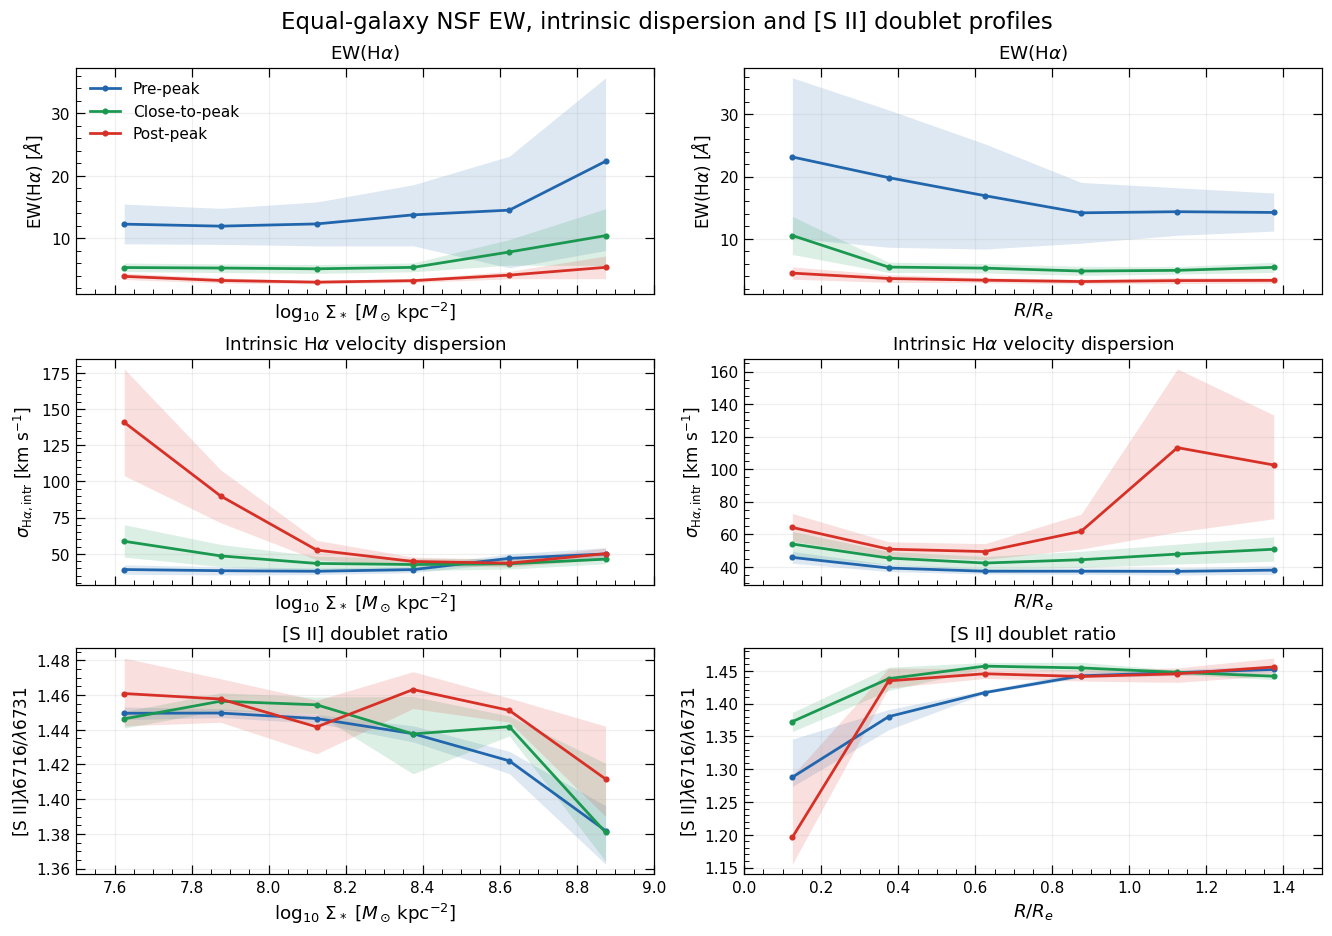

Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/NSF_EW_Halpha_sigma_SII_doublet_profiles_pooled_spaxel.png
Saved: /Users/Igniz/Desktop/ICRAR/further/Plot_Paper_2/NSF_EW_Halpha_sigma_SII_doublet_profiles_pooled_spaxel.pdf


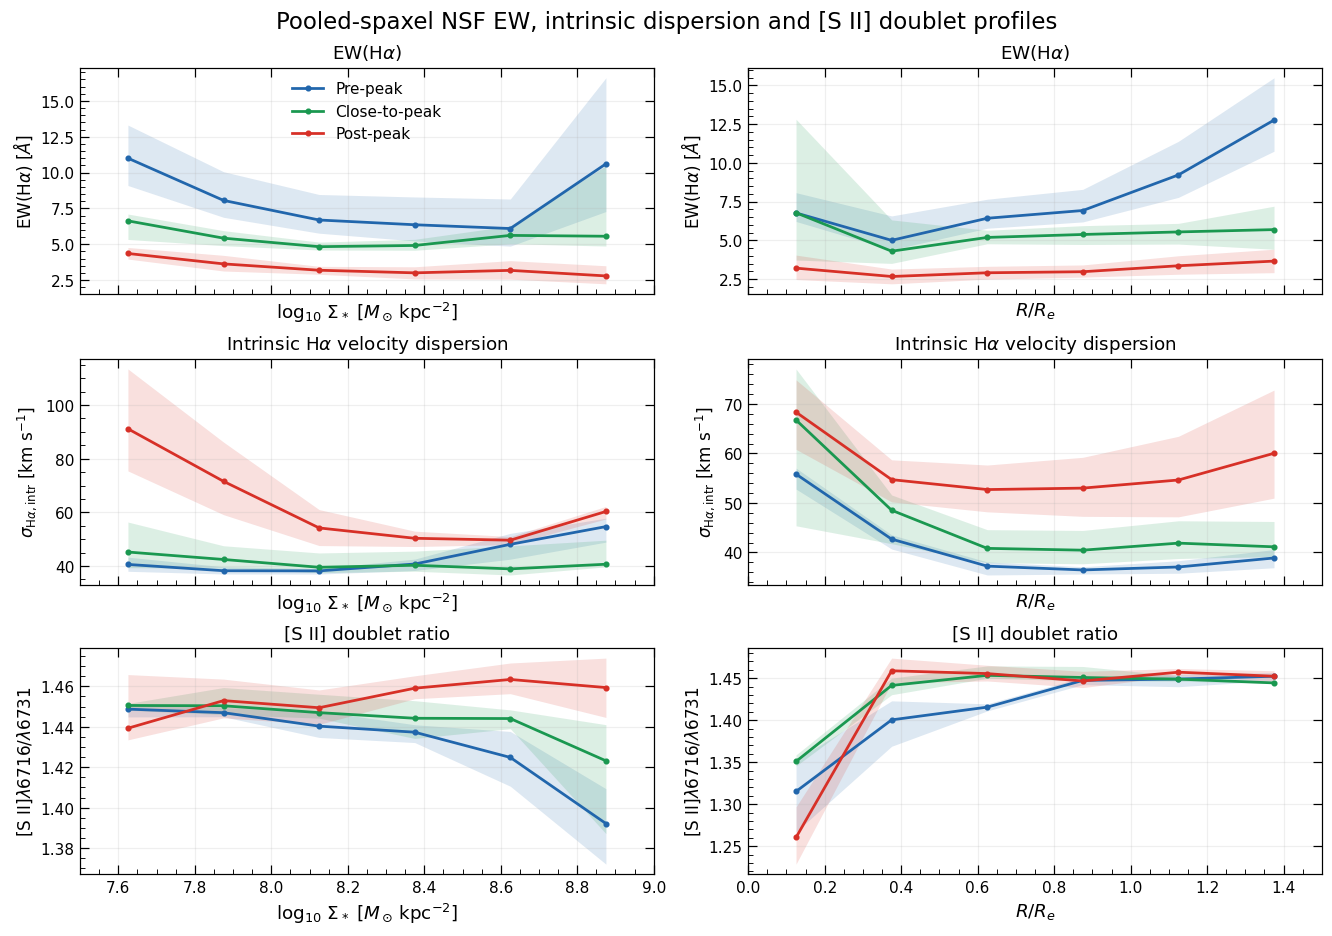

In [17]:
NSF_EXTRA_LABELS={
    'EW_Ha':(r'EW(H$\alpha$)',r'EW(H$\alpha$) [$\AA$]'),
    'sigma_Ha_intrinsic':(r'Intrinsic H$\alpha$ velocity dispersion',r'$\sigma_{\mathrm{H}\alpha,\mathrm{intr}}$ [km s$^{-1}$]'),
    'SII_doublet':(r'[S II] doublet ratio',r'[S II]$\lambda6716/\lambda6731$'),
}
def plot_nsf_extra_diagnostics(branch):
    branch_label='Equal-galaxy' if branch=='equal_galaxy' else 'Pooled-spaxel'
    fig_extra,axes_extra=plt.subplots(3,2,figsize=(12,8.4),squeeze=False,sharex='col',layout='constrained')
    for row,diagnostic in enumerate(NSF_EXTRA_DIAGNOSTICS):
        for column,variable in enumerate(('log_sigma_star','radius_re')):
            ax=axes_extra[row,column]
            for stage in (1,2,3):
                panel=nsf_extra_profiles.loc[nsf_extra_profiles.branch.eq(branch)&
                    nsf_extra_profiles.stage.eq(stage)&nsf_extra_profiles.variable.eq(variable)&
                    nsf_extra_profiles.diagnostic.eq(diagnostic)].sort_values('center')
                x=panel.center.to_numpy(float)
                ax.plot(x,panel.value.to_numpy(float),color=STAGE_COLORS[stage],marker='o',ms=3,lw=1.8,label=STAGE_LABELS[stage])
                ax.fill_between(x,panel.lo.to_numpy(float),panel.hi.to_numpy(float),color=STAGE_COLORS[stage],alpha=0.15,linewidth=0)
            ax.set_xlim(FRACTION_EDGES[variable][0],FRACTION_EDGES[variable][-1])
            ax.set_title(NSF_EXTRA_LABELS[diagnostic][0],fontsize=12)
            ax.set_ylabel(NSF_EXTRA_LABELS[diagnostic][1],fontsize=11)
            ax.set_xlabel(fraction_labels[variable],fontsize=12)
            ax.tick_params(labelsize=10,top=True,right=True);ax.minorticks_on();ax.grid(alpha=0.2)
    axes_extra[0,0].legend(frameon=False,fontsize=10,loc='best')
    fig_extra.suptitle(branch_label+' NSF EW, intrinsic dispersion and [S II] doublet profiles',fontsize=15)
    stem='NSF_EW_Halpha_sigma_SII_doublet_profiles_'+branch
    save_figure(fig_extra,stem)
    plt.show();plt.close(fig_extra)
for extra_branch in ('equal_galaxy','pooled_spaxel'):
    plot_nsf_extra_diagnostics(extra_branch)
